In [ ]:

%pip -q install "pandas==2.2.3" "google-auth==2.49.0" "google-genai>=1.40,<2.0" "PyMuPDF>=1.24,<1.28" "tiktoken>=0.8,<1.0"

import os, re, json, time, random, hashlib, getpass
from pathlib import Path
from collections import OrderedDict
from datetime import datetime, timezone
import fitz
import pandas as pd
import tiktoken
from google import genai
from google.genai import types
from IPython.display import display

# Project configuration
PDF_NAME = "24142071 Tuvalu 2025-2026.pdf"
ROOT = Path("/content/Tuvalu_IMF_Task1")
CACHE = ROOT / "cache"
ROOT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

MODEL = "gemini-3.5-flash-lite"
CHUNK_SIZE = 420
OVERLAP = 50
VERSION = "tuvalu_task1_final_v2"

# Locate PDF already uploaded into Colab
locations = [
    Path("/content") / PDF_NAME,
    Path.cwd() / PDF_NAME,
    Path("/mnt/data") / PDF_NAME
]
PDF = next((p for p in locations if p.is_file()), None)
if PDF is None:
    raise FileNotFoundError(
        f"{PDF_NAME} not found. Upload it to Colab Files."
    )

with fitz.open(PDF) as doc:
    N_PAGES = len(doc)
    first_page = doc[0].get_text()

assert N_PAGES == 78, f"Unexpected page count: {N_PAGES}"
assert "TUVALU" in first_page.upper(), "Country mismatch."
assert "2025" in first_page, "Report year mismatch."

PDF_HASH = hashlib.sha256(PDF.read_bytes()).hexdigest()

# Obtain API key securely
key = os.environ.get("GEMINI_API_KEY")
if not key:
    try:
        from google.colab import userdata
        key = userdata.get("GEMINI_API_KEY")
    except Exception:
        pass
if not key:
    key = getpass.getpass("Enter Gemini API key: ")
if not key:
    raise ValueError("Gemini API key is required.")

client = genai.Client(
    api_key=key,
    http_options=types.HttpOptions(timeout=120000)
)

tokenizer = tiktoken.get_encoding("cl100k_base")

def count_tokens(text):
    return len(tokenizer.encode(text, disallowed_special=()))

def save_json(path, data):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )
    tmp.replace(path)

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

# Test API and model access
try:
    response = client.models.generate_content(
        model=MODEL,
        contents="Reply with exactly READY.",
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=100
        )
    )
    assert response.text and "READY" in response.text.upper()
except Exception as e:
    raise RuntimeError(
        f"Gemini API/model connection failed: {e}"
    ) from e

print("ENVIRONMENT READY")
print("Country: Tuvalu")
print("PDF:", PDF.name)
print("Pages:", N_PAGES)
print("Model:", MODEL)
print("API connection: Successful")
print("Output directory:", ROOT)


ENVIRONMENT READY
Country: Tuvalu
PDF: 24142071 Tuvalu 2025-2026.pdf
Pages: 78
Model: gemini-3.5-flash-lite
API connection: Successful
Output directory: /content/Tuvalu_IMF_Task1


In [ ]:

# Extract and clean page text
def clean_text(raw):
    raw = raw.replace("\u00ad", "").replace("\u00a0", " ")
    raw = raw.replace("\ufb01", "fi").replace("\ufb02", "fl")
    raw = re.sub(r"(?<=\w)-\n(?=[a-z])", "", raw)

    lines = []
    for line in raw.splitlines():
        line = re.sub(r"[ \t]+", " ", line).strip()
        if re.fullmatch(r"TUVALU", line, re.I):
            continue
        if re.fullmatch(r"INTERNATIONAL MONETARY FUND", line, re.I):
            continue
        if re.fullmatch(r"\d{1,3}", line):
            continue
        lines.append(line)

    text = "\n".join(lines)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

with fitz.open(PDF) as doc:
    pages = [
        clean_text(p.get_text("text", sort=True))
        for p in doc
    ]

assert len(pages) == 78
assert all(len(p) > 50 for p in pages), (
    "A page contains too little extracted text."
)

page_records = [
    {"pdf_page": i + 1, "text": t}
    for i, t in enumerate(pages)
]
save_json(ROOT / "page_records.json", page_records)

(ROOT / "cleaned_report.txt").write_text(
    "\n\n".join(
        f"=== PDF PAGE {i+1} ===\n{t}"
        for i, t in enumerate(pages)
    ),
    encoding="utf-8"
)

def join_pages(start, end):
    return "\n\n".join(
        f"[PDF page {i}]\n{pages[i-1]}"
        for i in range(start, end + 1)
    )

sections = OrderedDict()

def add_section(name, text, start, end):
    if not text.strip():
        raise ValueError(f"Empty section: {name}")
    sections[name] = {
        "text": text.strip(),
        "pdf_pages": [start, end],
        "tokens": count_tokens(text)
    }

# Front matter
add_section(
    "Press Release and Executive Board Assessment",
    join_pages(2, 4), 2, 4
)
add_section(
    "Staff Report - Key Issues",
    join_pages(5, 5), 5, 5
)

# Main staff report, pages 8-24
# Detect section headings on the source pages, not the TOC.
heading_specs = [
    ("Context", r"^CONTEXT\s*$"),
    ("Recent Developments", r"^RECENT DEVELOPMENTS\s*$"),
    ("Outlook and Risks", r"^OUTLOOK AND RISKS\s*$"),
    ("Policy Discussion - Overview", r"^POLICY DISCUSSION:"),
    ("Fiscal Policy", r"^A\.\s+Fiscal Policy:"),
    ("Financial Sector Policies", r"^B\.\s+Financial Sector Policies:"),
    ("Structural Reforms", r"^C\.\s+Structural Reforms:"),
    ("Capacity Development and Data Issues",
     r"^D\.\s+Capacity Development and Data Issues"),
    ("Staff Appraisal", r"^STAFF APPRAISAL\s*$")
]

main_parts = []
for page_no in range(8, 25):
    main_parts.append((page_no, pages[page_no-1]))

main_text = ""
page_positions = []
for page_no, text in main_parts:
    page_positions.append((len(main_text), page_no))
    main_text += text + "\n\n"

hits = []
for name, pattern in heading_specs:
    match = re.search(
        pattern, main_text,
        flags=re.MULTILINE | re.IGNORECASE
    )
    if match is None:
        raise ValueError(
            f"Cannot locate heading '{name}'. "
            "Check extraction formatting before continuing."
        )
    hits.append((match.start(), name))

hits.sort()

def page_at(position):
    result = 8
    for offset, page_no in page_positions:
        if offset > position:
            break
        result = page_no
    return result

for i, (start, name) in enumerate(hits):
    end = hits[i+1][0] if i+1 < len(hits) else len(main_text)
    add_section(
        name,
        main_text[start:end],
        page_at(start),
        page_at(max(start, end-1))
    )

# Statistical figures and tables
add_section(
    "Statistical Figures and Tables",
    join_pages(25, 32), 25, 32
)

# Individual report annexes
annexes = [
    ("Annex I - Country Engagement Strategy", 33, 36),
    ("Annex II - Natural Disasters", 37, 38),
    ("Annex III - Previous Recommendations", 39, 39),
    ("Annex IV - Import Dependence and Inflation", 40, 41),
    ("Annex V - External Sector Assessment", 42, 44),
    ("Annex VI - Risk Assessment Matrix", 45, 46),
    ("Annex VII - Data Issues", 47, 48)
]

for name, start, end in annexes:
    add_section(name, join_pages(start, end), start, end)

# Other components of the complete report package
add_section(
    "Informational Annex",
    join_pages(49, 53), 49, 53
)
add_section(
    "Debt Sustainability Analysis",
    join_pages(54, 73), 54, 73
)
add_section(
    "Alternate Executive Directors Statement",
    join_pages(74, 78), 74, 78
)

assert len(sections) == 22, (
    f"Expected 22 sections, found {len(sections)}"
)

# Token-aware overlapping chunks
def chunk_text(text, target=420, overlap=50):
    if overlap < 0 or overlap >= target:
        raise ValueError("Invalid chunk overlap.")

    ids = tokenizer.encode(text, disallowed_special=())
    output, start = [], 0

    while start < len(ids):
        end = min(start + target, len(ids))

        if end < len(ids):
            sample = tokenizer.decode(ids[start:end])
            boundaries = list(re.finditer(
                r"(?:[.!?](?=\s)|\n\n)", sample
            ))
            if boundaries:
                proposed = count_tokens(
                    sample[:boundaries[-1].end()]
                )
                if proposed >= 260:
                    end = start + proposed

        if end <= start:
            end = min(start + target, len(ids))

        content = tokenizer.decode(ids[start:end]).strip()
        if content:
            output.append({
                "text": content,
                "token_count": count_tokens(content)
            })

        if end == len(ids):
            break

        start = max(start+1, end-overlap)

    return output

all_chunks = []
for name, item in sections.items():
    for c in chunk_text(item["text"], CHUNK_SIZE, OVERLAP):
        all_chunks.append({
            "chunk_id": f"C{len(all_chunks):04d}",
            "section": name,
            "pdf_pages": item["pdf_pages"],
            **c
        })

assert all(
    c["token_count"] <= CHUNK_SIZE + 10 for c in all_chunks
)

save_json(ROOT / "chunks.json", all_chunks)
save_json(ROOT / "section_manifest.json", [
    {
        "section": name,
        "pdf_pages": item["pdf_pages"],
        "tokens": item["tokens"]
    }
    for name, item in sections.items()
])

manifest = pd.DataFrame([
    {
        "Section": name,
        "PDF pages": str(item["pdf_pages"]),
        "Tokens": item["tokens"]
    }
    for name, item in sections.items()
])

print("PDF extraction: PASS")
print("Pages processed:", len(pages))
print("Sections identified:", len(sections))
print("Chunks generated:", len(all_chunks))
print("Chunk target:", CHUNK_SIZE)
print("Overlap:", OVERLAP)
display(manifest)


PDF extraction: PASS
Pages processed: 78
Sections identified: 22
Chunks generated: 171
Chunk target: 420
Overlap: 50


,Section,PDF pages,Tokens
0,Press Release and Executive Board Assessment,"[2, 4]",2422
1,Staff Report - Key Issues,"[5, 5]",372
2,Context,"[8, 9]",1415
3,Recent Developments,"[10, 11]",1140
4,Outlook and Risks,"[11, 13]",1905
5,Policy Discussion - Overview,"[14, 14]",161
6,Fiscal Policy,"[14, 18]",2406
7,Financial Sector Policies,"[18, 20]",1597
8,Structural Reforms,"[20, 22]",1041
9,Capacity Development and Data Issues,"[22, 22]",318


In [ ]:

# Gemini request wrapper with persistent response caching
def gemini_call(system, prompt, max_tokens=500,
                json_mode=False, temperature=0.1,
                max_attempts=8):

    payload = {
        "version": VERSION,
        "pdf_hash": PDF_HASH,
        "model": MODEL,
        "system": system,
        "prompt": prompt,
        "max_tokens": max_tokens,
        "json_mode": json_mode,
        "temperature": temperature
    }

    digest = hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode()
    ).hexdigest()
    cache_file = CACHE / f"{digest}.json"

    if cache_file.exists():
        return read_json(cache_file)["response"]

    for attempt in range(max_attempts):
        try:
            settings = {
                "system_instruction": system,
                "temperature": temperature,
                "max_output_tokens": max_tokens
            }
            if json_mode:
                settings["response_mime_type"] = "application/json"

            result = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(**settings)
            )

            answer = (result.text or "").strip()
            if not answer:
                raise ValueError("Empty model response.")

            if json_mode:
                json.loads(answer)

            save_json(cache_file, {
                "model": MODEL,
                "response": answer,
                "timestamp": datetime.now(
                    timezone.utc
                ).isoformat()
            })
            return answer

        except Exception as exc:
            code = getattr(exc, "code", None)
            try:
                code = int(code)
            except (TypeError, ValueError):
                code = None

            if code in (400, 401, 403, 404):
                raise RuntimeError(
                    f"Non-retryable Gemini error ({code}): {exc}"
                ) from exc

            message = str(exc)
            if (
                code == 429 and
                "perday" in message.lower().replace(" ", "")
            ):
                raise RuntimeError(
                    "Gemini daily quota exhausted. "
                    "Existing responses are cached. "
                    "Resume when quota becomes available."
                ) from exc

            if attempt + 1 >= max_attempts:
                raise RuntimeError(
                    "Gemini retries exhausted. "
                    "Cached results remain available. "
                    f"Last error: {exc}"
                ) from exc

            wait = min(120, 5 * (2 ** attempt))
            wait += random.uniform(0, 2)

            retry = re.search(
                r"(?:retry(?:Delay| after)?)[^\d]*"
                r"(\d+(?:\.\d+)?)\s*s",
                message, re.I
            )
            if retry:
                wait = max(wait, float(retry.group(1)))

            print(
                f"API retry {attempt+1}/{max_attempts}; "
                f"waiting {wait:.1f}s"
            )
            time.sleep(wait)

# Extractor directive
SUMMARIZER = """
You are an IMF macroeconomic report analyst.
Summarise strictly from the supplied source.
Preserve numerical values, years, policy findings,
financial risks and institutional names.
Distinguish historical observations from forecasts.
Never invent missing data or unsupported details.
Use concise professional British English.
"""

# Independent automated judge prompt loop
JUDGE = """
You are a critical reviewer of IMF country report summaries.
Evaluate against the available evidence only.
Judge consistency, completeness and factual alignment
independently on a 0 to 5 scale.

Consistency: absence of contradictions and logical errors.
Completeness: coverage of material source findings.
Factual alignment: fidelity to supported facts, numbers,
years, institutions and forecasts.

0 = unacceptable, 1 = poor, 2 = weak,
3 = acceptable, 4 = good, 5 = excellent.

Do not reward eloquence when facts are unsupported.
Return only valid JSON when requested.
"""

def words(text):
    return len(re.findall(r"\b[\w]+(?:[-’'][\w]+)*\b", text))

def split_evidence(text, target=2300):
    return chunk_text(text, target=target, overlap=100)

print("GEMINI FRAMEWORK READY")
print("Summarizer model:", MODEL)
print("Evaluator: Automated independent judge prompt loop")
print("Caching: Enabled")
print("Prompt version:", VERSION)


GEMINI FRAMEWORK READY
Summarizer model: gemini-3.5-flash-lite
Evaluator: Automated independent judge prompt loop
Caching: Enabled
Prompt version: tuvalu_task1_final_v2


In [ ]:


# TASK 1: SECTION + EXECUTIVE SUMMARISATION
# Gemini | Resume Support | Word-Limit Validation | Caching

# ---------------- 1. Evidence Extraction ----------------

MAP_PROMPT = SUMMARIZER + """
Extract compact factual notes from the supplied IMF source.

Requirements:
- Maximum 150 words.
- Preserve important numbers, dates, forecasts and institutions.
- Include major economic findings, financial risks and policies.
- Distinguish historical observations from projections.
- Never invent information.
- Do not add external knowledge.
"""

def evidence_for_section(name, text):
    """Prepare evidence from all parts of a report section."""

    if count_tokens(text) <= 3000:
        return text

    pieces = split_evidence(text)
    notes = []

    for i, piece in enumerate(pieces, 1):
        note = gemini_call(
            MAP_PROMPT,
            f"SECTION: {name}\n"
            f"EVIDENCE WINDOW: {i}/{len(pieces)}\n\n"
            f"SOURCE:\n{piece['text']}\n\n"
            "Extract the most important factual evidence.",
            max_tokens=350
        )
        notes.append(note)

    # Consolidate evidence without ignoring later windows.
    while count_tokens("\n\n".join(notes)) > 4500:
        condensed = []

        for j in range(0, len(notes), 5):
            group = notes[j:j + 5]

            result = gemini_call(
                MAP_PROMPT,
                f"SECTION: {name}\n\n"
                "Consolidate the following factual evidence. "
                "Preserve distinct numerical findings, risks "
                "and policy recommendations:\n\n"
                + "\n\n".join(group),
                max_tokens=450
            )
            condensed.append(result)

        if len(condensed) >= len(notes):
            raise RuntimeError(
                f"Evidence compression stalled: {name}"
            )

        notes = condensed

    return "\n\n".join(notes)


# ---------------- 2. Section Summary Prompt ----------------

SECTION_PROMPT = SUMMARIZER + """
Write a concise, factual section summary.

STRICT REQUIREMENTS:
1. Target 65–80 words.
2. Never exceed 90 words.
3. Preserve the most important numerical findings.
4. Distinguish historical results from projections.
5. Include important economic risks and policy implications.
6. Avoid unnecessary introductory sentences.
7. Use one coherent paragraph.
8. Do not include headings or bullet points.
9. Never invent unsupported facts.
"""


# ---------------- 3. Word-Limit Control ----------------

def shorten_summary(summary, max_words=95):
    """
    Deterministic fallback:
    preserve complete sentences within the word limit.
    """

    sentences = re.split(
        r"(?<=[.!?])\s+",
        summary.strip()
    )

    kept = []

    for sentence in sentences:
        candidate = " ".join(kept + [sentence])

        if words(candidate) <= max_words:
            kept.append(sentence)
        else:
            break

    result = " ".join(kept).strip()

    if result and words(result) >= 15:
        return result

    # If one sentence is extremely long, truncate at a word
    # boundary. This is only a last-resort safeguard.
    tokens = summary.strip().split()
    result = " ".join(tokens[:90]).rstrip(",;: ")

    if result and result[-1] not in ".!?":
        result += "."

    return result


# ---------------- 4. Generate Section Summary ----------------

def generate_section(name, item):
    evidence = evidence_for_section(
        name,
        item["text"]
    )

    prompt = (
        "REPORT: Tuvalu 2025 Article IV Consultation\n"
        f"SECTION: {name}\n"
        f"PDF PAGES: {item['pdf_pages']}\n\n"
        f"SOURCE EVIDENCE:\n{evidence}\n\n"
        "Summarise this section in 65–80 words. "
        "Preserve key numerical evidence, major findings, "
        "financial risks and policy recommendations. "
        "Never exceed 90 words."
    )

    summary = gemini_call(
        SECTION_PROMPT,
        prompt,
        max_tokens=300
    ).strip()

    # Retry with stronger constraints if Gemini exceeds limit.
    for attempt in range(3):

        if words(summary) < 100:
            break

        summary = gemini_call(
            SECTION_PROMPT,
            (
                "Rewrite the following summary into "
                "65–80 words, maximum 90 words. "
                "Remove less important details first, "
                "but retain accurate statistics, dates, "
                "major risks and recommendations.\n\n"
                + summary
            ),
            max_tokens=260,
            temperature=0
        ).strip()

    # Deterministic final fallback.
    if words(summary) >= 100:
        summary = shorten_summary(summary)

    if not 15 <= words(summary) < 100:
        raise ValueError(
            f"Invalid summary length for {name}: "
            f"{words(summary)} words."
        )

    return summary, evidence


# ---------------- 5. Resume Existing Summaries ----------------

summary_file = ROOT / "section_summaries.json"
evidence_file = ROOT / "section_evidence.json"

summaries = OrderedDict()
evidence_bank = {}

if summary_file.exists():
    previous = read_json(summary_file)

    for name, value in previous.items():
        if (
            name in sections
            and isinstance(value, dict)
            and value.get("summary")
            and words(value["summary"]) < 100
        ):
            summaries[name] = value

if evidence_file.exists():
    evidence_bank = read_json(evidence_file)

print("Previously completed sections:", len(summaries))


# ---------------- 6. Summarise Every Section ----------------

total_sections = len(sections)

for index, (name, item) in enumerate(
    sections.items(), 1
):

    if name in summaries and name in evidence_bank:
        print(
            f"[{index}/{total_sections}] "
            f"Cached: {name}"
        )
        continue

    print(
        f"[{index}/{total_sections}] "
        f"Summarising: {name}"
    )

    summary, evidence = generate_section(
        name, item
    )

    summaries[name] = {
        "summary": summary,
        "word_count": words(summary),
        "pdf_pages": item["pdf_pages"]
    }

    evidence_bank[name] = evidence

    # Save progress immediately after each section.
    save_json(summary_file, summaries)
    save_json(evidence_file, evidence_bank)

    print(
        f"  Completed — {words(summary)} words"
    )


# ---------------- 7. Validate Section Summaries ----------------

assert len(summaries) == total_sections, (
    "Not all source sections have summaries."
)

assert all(
    words(summaries[name]["summary"]) < 100
    for name in sections
), "One or more summaries exceed the word limit."

print("\nSECTION SUMMARISATION COMPLETED")
print("Total sections:", total_sections)
print("All summaries below 100 words: PASS")


# ---------------- 8. Executive Summary ----------------

executive_context = "\n\n".join(
    f"{name}:\n{summaries[name]['summary']}"
    for name in sections
)

EXEC_PROMPT = SUMMARIZER + """
Prepare exactly SEVEN executive summary bullet points
for the complete IMF Tuvalu Article IV report.

Cover these topics:

1. Economic recovery and GDP growth outlook.
2. Inflation and external-sector vulnerabilities.
3. Fiscal sustainability, government debt and reserves.
4. Banking sector soundness and financial regulation.
5. Climate change and natural disaster exposure.
6. Structural challenges, migration and development.
7. Main IMF policy recommendations.

Requirements:
- Use only supplied evidence.
- Preserve important numerical facts and years.
- Distinguish actual outcomes from projections.
- Prioritise national financial stability implications.
- Avoid repeating the same finding.
- Keep each bullet concise and informative.

Return valid JSON:
{
  "bullets": [
    "bullet 1",
    "bullet 2",
    "bullet 3",
    "bullet 4",
    "bullet 5",
    "bullet 6",
    "bullet 7"
  ]
}
"""

executive_raw = gemini_call(
    EXEC_PROMPT,
    (
        "REPORT: Tuvalu 2025 Article IV Consultation\n\n"
        "Evidence from all report sections:\n\n"
        + executive_context
    ),
    max_tokens=1200,
    json_mode=True
)

executive_data = json.loads(executive_raw)
bullets = executive_data.get("bullets", [])

if not isinstance(bullets, list) or len(bullets) != 7:
    raise ValueError(
        "Executive summary must contain exactly 7 bullets."
    )

if not all(
    isinstance(b, str) and b.strip()
    for b in bullets
):
    raise ValueError(
        "Executive summary contains invalid bullets."
    )

executive_summary = "\n".join(
    "- " + bullet.strip()
    for bullet in bullets
)


# ---------------- 9. Save Final Outputs ----------------

(ROOT / "executive_summary.md").write_text(
    executive_summary,
    encoding="utf-8"
)

(ROOT / "section_summaries.md").write_text(
    "\n\n".join(
        f"## {name}\n\n{summaries[name]['summary']}"
        for name in sections
    ),
    encoding="utf-8"
)

save_json(
    ROOT / "task1_summarisation_results.json",
    {
        "country": "Tuvalu",
        "report_year": 2025,
        "model": MODEL,
        "pdf_hash": PDF_HASH,
        "executive_bullets": bullets,
        "section_summaries": summaries
    }
)


# ---------------- 10. Display Results ----------------

print("\n" + "=" * 65)
print("TASK 1 — EXECUTIVE SUMMARY")
print("=" * 65)

print(executive_summary)

print("\n" + "=" * 65)
print("SECTION SUMMARY VALIDATION")
print("=" * 65)

summary_table = pd.DataFrame([
    {
        "Section": name,
        "Words": words(summaries[name]["summary"]),
        "PDF Pages": str(
            summaries[name]["pdf_pages"]
        )
    }
    for name in sections
])

display(summary_table)

print("\nTotal sections:", len(summaries))
print("Executive bullets:", len(bullets))
print("All section summaries < 100 words: PASS")
print("Progress saved:", summary_file)
print("\nCELL 4 COMPLETED SUCCESSFULLY")


Previously completed sections: 3
[1/22] Cached: Press Release and Executive Board Assessment
[2/22] Cached: Staff Report - Key Issues
[3/22] Cached: Context
[4/22] Summarising: Recent Developments
  Completed — 93 words
[5/22] Summarising: Outlook and Risks
  Completed — 83 words
[6/22] Summarising: Policy Discussion - Overview
  Completed — 72 words
[7/22] Summarising: Fiscal Policy
  Completed — 81 words
[8/22] Summarising: Financial Sector Policies
  Completed — 88 words
[9/22] Summarising: Structural Reforms
  Completed — 90 words
[10/22] Summarising: Capacity Development and Data Issues
  Completed — 74 words
[11/22] Summarising: Staff Appraisal
  Completed — 70 words
[12/22] Summarising: Statistical Figures and Tables
  Completed — 88 words
[13/22] Summarising: Annex I - Country Engagement Strategy
  Completed — 85 words
[14/22] Summarising: Annex II - Natural Disasters
  Completed — 84 words
[15/22] Summarising: Annex III - Previous Recommendations
  Completed — 80 words
[16/22]

,Section,Words,PDF Pages
0,Press Release and Executive Board Assessment,96,"[2, 4]"
1,Staff Report - Key Issues,88,"[5, 5]"
2,Context,98,"[8, 9]"
3,Recent Developments,93,"[10, 11]"
4,Outlook and Risks,83,"[11, 13]"
5,Policy Discussion - Overview,72,"[14, 14]"
6,Fiscal Policy,81,"[14, 18]"
7,Financial Sector Policies,88,"[18, 20]"
8,Structural Reforms,90,"[20, 22]"
9,Capacity Development and Data Issues,74,"[22, 22]"



Total sections: 22
Executive bullets: 7
All section summaries < 100 words: PASS
Progress saved: /content/Tuvalu_IMF_Task1/section_summaries.json

CELL 4 COMPLETED SUCCESSFULLY


In [ ]:

# Build judge evidence with original-source excerpts
def judge_context(text, notes, summary, budget=3500):
    if count_tokens(text) <= budget:
        return text

    ids = tokenizer.encode(text, disallowed_special=())

    # Beginning, middle and end of original section
    beginning = tokenizer.decode(ids[:550])
    midpoint = len(ids)//2
    middle = tokenizer.decode(
        ids[max(0, midpoint-275):midpoint+275]
    )
    ending = tokenizer.decode(ids[-550:])

    # Retrieve additional relevant source paragraphs
    keywords = set(re.findall(
        r"[a-z]{5,}", summary.lower()
    ))
    paragraphs = [
        p.strip() for p in re.split(r"\n\s*\n", text)
        if len(p.strip()) > 50
    ]
    ranked = sorted(
        paragraphs,
        key=lambda p: len(
            keywords.intersection(
                set(re.findall(r"[a-z]{5,}", p.lower()))
            )
        ),
        reverse=True
    )

    selected = []
    used = 0
    for paragraph in ranked:
        n = count_tokens(paragraph)
        if n <= 220 and used+n <= 650:
            selected.append(paragraph)
            used += n

    note_ids = tokenizer.encode(
        notes, disallowed_special=()
    )
    note_text = tokenizer.decode(note_ids[:850])

    return (
        "[SOURCE BEGINNING]\n" + beginning
        + "\n[SOURCE MIDDLE]\n" + middle
        + "\n[SOURCE END]\n" + ending
        + "\n[RELEVANT SOURCE EXCERPTS]\n"
        + "\n".join(selected)
        + "\n[FULL-SECTION CONSOLIDATED NOTES]\n"
        + note_text
    )

AUDIT_PROMPT = """
Evaluate the generated summary against the source evidence.

Give three independent numeric scores, from 0 to 5:

consistency: Logical and source consistency.
completeness: Coverage of significant material.
factual_alignment: Accuracy and source support.

Consider missing risks, incorrectly stated data,
unsupported claims and forecast/history confusion.

Return a JSON object with exactly these keys:
{
  "consistency": 0,
  "completeness": 0,
  "factual_alignment": 0,
  "missing_points": [],
  "unsupported_claims": [],
  "reason": "Brief critical explanation"
}
"""

def evaluate(name, source, summary):
    raw = gemini_call(
        JUDGE,
        f"SECTION: {name}\n\n"
        f"SOURCE EVIDENCE:\n{source}\n\n"
        f"SUMMARY TO EVALUATE:\n{summary}\n\n"
        + AUDIT_PROMPT,
        max_tokens=650,
        json_mode=True,
        temperature=0
    )

    result = json.loads(raw)
    metrics = [
        "consistency", "completeness", "factual_alignment"
    ]

    for metric in metrics:
        if metric not in result:
            raise ValueError(
                f"Missing evaluation metric: {metric}"
            )
        value = result[metric]
        if isinstance(value, bool) or not isinstance(
            value, (int, float)
        ):
            raise ValueError(
                f"Non-numeric evaluation score: {metric}"
            )
        if not 0 <= value <= 5:
            raise ValueError(
                f"Out-of-range score: {metric}={value}"
            )

    for field in ("missing_points", "unsupported_claims"):
        if not isinstance(result.get(field), list):
            raise ValueError(f"Invalid judge field: {field}")

    if not isinstance(result.get("reason"), str):
        raise ValueError("Judge reasoning missing.")

    result["mean_score"] = round(
        sum(result[k] for k in metrics)/3, 2
    )
    return result

judge_file = ROOT / "judge_evaluations.json"
judgements = read_json(judge_file) if judge_file.exists() else {}

for i, (name, item) in enumerate(sections.items(), 1):
    if name in judgements:
        print(f"[{i}/22] Cached evaluation: {name}")
        continue

    print(f"[{i}/22] Evaluating: {name}")

    source = judge_context(
        item["text"],
        evidence_bank[name],
        summaries[name]["summary"]
    )

    result = evaluate(
        name, source, summaries[name]["summary"]
    )
    judgements[name] = result
    save_json(judge_file, judgements)

    print(f"  Judge score: {result['mean_score']}/5")

# Audit executive summary against full-report section evidence
if "Executive Summary" not in judgements:
    executive_evidence = "\n\n".join(
        f"{name}: {summaries[name]['summary']}"
        for name in sections
    )
    judgements["Executive Summary"] = evaluate(
        "Executive Summary",
        executive_evidence,
        executive_summary
    )
    save_json(judge_file, judgements)

# Create score table
rows = []
for name in sections:
    audit = judgements[name]
    rows.append({
        "Section": name,
        "Words": words(summaries[name]["summary"]),
        "Consistency": audit["consistency"],
        "Completeness": audit["completeness"],
        "Factual Alignment": audit["factual_alignment"],
        "Mean Score": audit["mean_score"]
    })

scores = pd.DataFrame(rows)
scores.to_csv(ROOT / "evaluation_scores.csv", index=False)

metrics = [
    "Consistency", "Completeness", "Factual Alignment"
]

validation = {
    "country": "Tuvalu",
    "report": PDF_NAME,
    "model": MODEL,
    "pages_processed": len(pages),
    "sections_identified": len(sections),
    "chunks_created": len(all_chunks),
    "summaries_completed": len(summaries),
    "section_evaluations": len(sections),
    "executive_bullets": len(bullets),
    "all_section_summaries_under_100_words": all(
        words(summaries[n]["summary"]) < 100
        for n in sections
    ),
    "mean_consistency": round(
        scores["Consistency"].mean(), 2
    ),
    "mean_completeness": round(
        scores["Completeness"].mean(), 2
    ),
    "mean_factual_alignment": round(
        scores["Factual Alignment"].mean(), 2
    ),
    "overall_section_judge_score": round(
        scores[metrics].to_numpy().mean(), 2
    ),
    "executive_judge_score":
        judgements["Executive Summary"]["mean_score"],
    "audit_limitation": (
        "Long sections use representative original excerpts "
        "and LLM-generated evidence notes. Judge scores are "
        "not independent human factual verification."
    )
}

assert len(summaries) == len(sections) == 22
assert len(bullets) == 7
assert validation["all_section_summaries_under_100_words"]

save_json(ROOT / "task1_validation.json", validation)

# Save one combined machine-readable output
save_json(ROOT / "task1_complete_results.json", {
    "metadata": validation,
    "executive_summary": bullets,
    "section_summaries": summaries,
    "judge_evaluations": judgements
})

print("\n" + "="*65)
print("TASK 1 EVALUATION RESULTS")
print("="*65)
display(scores)

print("\nSUMMARY STATISTICS")
for metric in metrics:
    print(f"{metric}: {scores[metric].mean():.2f}/5")
print(
    "Overall section judge:",
    validation["overall_section_judge_score"], "/5"
)
print(
    "Executive judge:",
    validation["executive_judge_score"], "/5"
)

print("\nFINAL VALIDATION")
print("Pages processed:", validation["pages_processed"])
print("Sections:", validation["sections_identified"])
print("Chunks:", validation["chunks_created"])
print("Section summaries:", validation["summaries_completed"])
print("Executive bullets:", validation["executive_bullets"])
print("Word constraints:", "PASS")
print("\nTASK 1 COMPLETED SUCCESSFULLY")

print("\nOutput files:")
for file in sorted(ROOT.iterdir()):
    if file.is_file():
        print(" -", file.name)


[1/22] Evaluating: Press Release and Executive Board Assessment
  Judge score: 5.0/5
[2/22] Evaluating: Staff Report - Key Issues
  Judge score: 5.0/5
[3/22] Evaluating: Context
  Judge score: 5.0/5
[4/22] Evaluating: Recent Developments
  Judge score: 4.67/5
[5/22] Evaluating: Outlook and Risks
  Judge score: 4.67/5
[6/22] Evaluating: Policy Discussion - Overview
  Judge score: 3.67/5
[7/22] Evaluating: Fiscal Policy
  Judge score: 4.67/5
[8/22] Evaluating: Financial Sector Policies
  Judge score: 4.67/5
[9/22] Evaluating: Structural Reforms
  Judge score: 4.67/5
[10/22] Evaluating: Capacity Development and Data Issues
  Judge score: 4.0/5
[11/22] Evaluating: Staff Appraisal
API retry 1/8; waiting 6.1s
  Judge score: 4.0/5
[12/22] Evaluating: Statistical Figures and Tables
  Judge score: 4.67/5
[13/22] Evaluating: Annex I - Country Engagement Strategy
  Judge score: 4.67/5
[14/22] Evaluating: Annex II - Natural Disasters
  Judge score: 4.67/5
[15/22] Evaluating: Annex III - Previous R

,Section,Words,Consistency,Completeness,Factual Alignment,Mean Score
0,Press Release and Executive Board Assessment,96,5,5,5,5.00
1,Staff Report - Key Issues,88,5,5,5,5.00
2,Context,98,5,5,5,5.00
3,Recent Developments,93,5,4,5,4.67
4,Outlook and Risks,83,5,4,5,4.67
5,Policy Discussion - Overview,72,4,4,3,3.67
6,Fiscal Policy,81,5,4,5,4.67
7,Financial Sector Policies,88,5,4,5,4.67
8,Structural Reforms,90,5,4,5,4.67
9,Capacity Development and Data Issues,74,4,4,4,4.00



SUMMARY STATISTICS
Consistency: 4.73/5
Completeness: 4.09/5
Factual Alignment: 4.64/5
Overall section judge: 4.48 /5
Executive judge: 5.0 /5

FINAL VALIDATION
Pages processed: 78
Sections: 22
Chunks: 171
Section summaries: 22
Executive bullets: 7
Word constraints: PASS

TASK 1 COMPLETED SUCCESSFULLY

Output files:
 - chunks.json
 - cleaned_report.txt
 - evaluation_scores.csv
 - executive_summary.md
 - judge_evaluations.json
 - page_records.json
 - section_evidence.json
 - section_manifest.json
 - section_summaries.json
 - section_summaries.md
 - task1_complete_results.json
 - task1_summarisation_results.json
 - task1_validation.json


In [ ]:

# ============================================================
# TASK 2: THEMES AND QUALITATIVE RISK INSIGHTS
# Reuses Gemini, cleaned pages and caching from Task 1
# ============================================================

import re, json
from collections import OrderedDict

assert len(pages) == 78
assert "gemini_call" in globals()
assert "sections" in globals()

T2 = ROOT / "task2"
T2.mkdir(parents=True, exist_ok=True)

# Seven mandatory IMF financial stability themes.
# These rules count matching textual passages, not token
# frequency or overlapping Task 1 chunks.
THEMES = OrderedDict({
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer pric", r"\bfood pric",
        r"\bcommodity pric", r"\bcost of living\b",
        r"\bprice pressures?\b", r"\bCPI\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rate", r"\bcredit growth\b",
        r"\blending\b", r"\bloan portfolio",
        r"\bcredit access\b", r"\bborrowing cost",
        r"\bcredit risk"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bland reclamation\b", r"\breclaimed land\b",
        r"\bproperty\b", r"\bmortgage"
    ],
    "Banking Capital & Liquidity": [
        r"\bcapital adequacy\b", r"\bbank capital\b",
        r"\bliquid assets\b", r"\bliquidity\b",
        r"\bcapital buffer", r"\bbanking sector\b",
        r"\bprudential\b", r"\bbank supervision\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bdebt distress\b",
        r"\bdebt sustainab", r"\bfiscal deficit",
        r"\bfiscal balance\b", r"\bsovereign debt\b",
        r"\bgovernment borrowing\b",
        r"\bdebt service\b"
    ],
    "Labor Market Dynamics": [
        r"\blabou?r force\b", r"\bunemployment\b",
        r"\bemployment\b", r"\bmigration\b",
        r"\bemigration\b", r"\bremittances?\b",
        r"\blabou?r shortages?\b",
        r"\bworkforce\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risk",
        r"\bfinancial sector risk", r"\bfinancial fragility\b",
        r"\bcorrespondent banking\b",
        r"\bexternal shocks?\b", r"\bclimate risks?\b",
        r"\bnatural disasters?\b", r"\bfiscal risks?\b",
        r"\bstress tests?\b"
    ]
})

compiled = {
    theme: [re.compile(p, re.I) for p in patterns]
    for theme, patterns in THEMES.items()
}

def normalise_space(text):
    return re.sub(r"\s+", " ", text).strip()

# Use original page boundaries; avoid double counting
# caused by the 50-token overlaps in Task 1 chunks.
passages = []
for page_no, page_text in enumerate(pages, 1):
    if page_no == 1:
        continue

    flat = normalise_space(page_text)
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9])", flat)

    for sentence in sentences:
        sentence = sentence.strip()
        if len(sentence) < 35:
            continue
        passages.append({
            "page": page_no,
            "text": sentence
        })

theme_counts = OrderedDict()
theme_evidence = OrderedDict()

for theme, patterns in compiled.items():
    matches = [
        p for p in passages
        if any(pattern.search(p["text"]) for pattern in patterns)
    ]
    theme_counts[theme] = len(matches)

    # Select a diverse set of source excerpts across PDF pages.
    # Avoid repeated excerpts from a single source page.
    selected, used_pages = [], set()
    for p in matches:
        if p["page"] not in used_pages:
            selected.append(p)
            used_pages.add(p["page"])
        if len(selected) >= 7:
            break

    theme_evidence[theme] = selected

assert len(theme_counts) == 7

save_json(T2 / "thematic_counts.json", {
    "country": "Tuvalu",
    "method": "Page-bounded matching passages using explicit theme rules",
    "count_unit": "matching text passage",
    "overlap_allowed": True,
    "theme_counts": theme_counts,
    "patterns": THEMES
})

# Build verifiable source references for Gemini.
evidence_catalog = OrderedDict()
for theme, matches in theme_evidence.items():
    for p in matches:
        eid = f"E{len(evidence_catalog)+1:03d}"
        evidence_catalog[eid] = {
            "theme": theme,
            "page": p["page"],
            "excerpt": p["text"][:700]
        }

# Add broad macroeconomic source evidence from important
# narrative sections, preventing keyword rules from
# determining all qualitative insights.
for name in [
    "Context", "Recent Developments", "Outlook and Risks",
    "Fiscal Policy", "Financial Sector Policies",
    "Structural Reforms", "Staff Appraisal"
]:
    item = sections[name]
    excerpt = normalise_space(item["text"])[:1100]
    eid = f"E{len(evidence_catalog)+1:03d}"
    evidence_catalog[eid] = {
        "theme": name,
        "page": item["pdf_pages"][0],
        "excerpt": excerpt
    }

save_json(T2 / "qualitative_evidence_catalog.json",
          evidence_catalog)

catalog_text = "\n\n".join(
    f"{eid} | PDF page {item['page']} | "
    f"{item['theme']} | {item['excerpt']}"
    for eid, item in evidence_catalog.items()
)

QUAL_SYSTEM = """
You are an IMF macroeconomic risk analyst.
Use ONLY the numbered source excerpts supplied.
Extract national economic strengths and vulnerabilities.
Do not invent findings or numerical statistics.
Every item must cite a valid source evidence ID.
Return a JSON object only.
"""

QUAL_PROMPT = """
Analyze the IMF 2025 Tuvalu report evidence below.

Return exactly six national macroeconomic strengths/growth
drivers and six systemic vulnerabilities/challenges.

Each item must be a concise, substantive statement grounded
in a provided excerpt.

Required JSON format:
{
  "strengths": [
    {"text": "Finding", "evidence_id": "E001"}
  ],
  "vulnerabilities": [
    {"text": "Finding", "evidence_id": "E002"}
  ]
}

Rules:
- Six items in each list.
- Use only evidence IDs that appear below.
- Avoid repeating equivalent findings.
- Include fiscal, financial and structural dimensions.
- Distinguish existing vulnerabilities from future risks.
- Do not invent unsupported quantitative claims.

SOURCE EVIDENCE:
""" + catalog_text

qualitative = json.loads(gemini_call(
    QUAL_SYSTEM,
    QUAL_PROMPT,
    max_tokens=1800,
    json_mode=True,
    temperature=0
))

for category in ("strengths", "vulnerabilities"):
    items = qualitative.get(category)
    assert isinstance(items, list) and len(items) == 6, (
        f"Expected six {category}."
    )

    for item in items:
        assert isinstance(item.get("text"), str)
        assert item["text"].strip()
        assert item.get("evidence_id") in evidence_catalog

        source = evidence_catalog[item["evidence_id"]]
        item["pdf_page"] = source["page"]
        item["source_excerpt"] = source["excerpt"]

save_json(T2 / "qualitative_insights.json", qualitative)

print("TASK 2 — THEMATIC DISTRIBUTION")
display(pd.DataFrame([
    {"Theme": theme, "Matching passages": count}
    for theme, count in theme_counts.items()
]))

print("\nMACROECONOMIC STRENGTHS")
for i, item in enumerate(qualitative["strengths"], 1):
    print(f"{i}. {item['text']} (PDF p. {item['pdf_page']})")

print("\nSYSTEMIC VULNERABILITIES")
for i, item in enumerate(qualitative["vulnerabilities"], 1):
    print(f"{i}. {item['text']} (PDF p. {item['pdf_page']})")

print("\nCELL 6 COMPLETED")


TASK 2 — THEMATIC DISTRIBUTION


,Theme,Matching passages
0,Inflation & Prices,57
1,Interest Rates & Credit,28
2,Housing & Real Estate,11
3,Banking Capital & Liquidity,23
4,Sovereign Debt,89
5,Labor Market Dynamics,41
6,Systemic Financial Risk,78



MACROECONOMIC STRENGTHS
1. Inflation has eased significantly from its pandemic peak of 14 percent in 2022Q3 to 1.2 percent in 2024, in line with global commodity prices and easing of shipping bottlenecks. (PDF p. 2)
2. GDP growth in 2024 is estimated to have reached 3.1 percent, supported by continued effects of reopening on domestic activities and major infrastructure projects including coastal adaptation, maritime transportation, and renewable energy. (PDF p. 10)
3. Credit risks for the TNPF are limited since its members' balances are used as collateral when it extends loans to its members. (PDF p. 18)
4. The capital adequacy ratio of the banking sector remained at a high level of around 120 percent at end-2024, and the NPL ratio of the NBT fell from 32.6 percent in 2019 to 21.2 percent in 2024, with provisioning coverage at 153.5 percent. (PDF p. 18)
5. Recent improvements in internet connectivity can be leveraged using IT technology to enhance the access and efficiency of public s

In [ ]:

# ============================================================
# TASK 2: STRICT JSON AND HISTORICAL INDICATORS
# Source tables: PDF pages 4 and 32
# ============================================================

import math

# Use the PDF's original page text, avoiding any potential
# line-wrap artifacts in the condensed Task 1 summaries.
with fitz.open(PDF) as doc:
    table1_text = doc[3].get_text("text", sort=True)
    table4_text = doc[31].get_text("text", sort=True)
    missing_context = doc[47].get_text("text", sort=True)

YEARS_MAIN = list(range(2022, 2031))
YEARS_BANK = list(range(2019, 2025))

NUMBER_RE = re.compile(r"""
    (?<![\w/])
    \(?-?\d+(?:\.\d+)?\)?
    (?![\w/])
""", re.X)

def get_row(table_text, label, expected):
    """
    Retrieve an IMF numeric table row by its printed label.
    Record the exact original source line for later validation.
    """
    candidates = [
        line.strip()
        for line in table_text.splitlines()
        if re.search(re.escape(label), line, re.I)
    ]

    for line in candidates:
        match = re.search(re.escape(label), line, re.I)
        suffix = line[match.end():]

        # Strip a footnote marker immediately after the label.
        suffix = re.sub(r"^\s*\d+/", "", suffix)

        values = []
        for token in NUMBER_RE.findall(suffix):
            negative = token.startswith("(") and token.endswith(")")
            value = float(token.strip("()"))
            values.append(-value if negative else value)

        if len(values) == expected:
            return values, line

    return None, None

# Extract comparable source-grounded annual series.
SERIES_SPECS = OrderedDict({
    "real_gdp_growth_pct":
        (table1_text, "Real GDP growth", YEARS_MAIN, 4),
    "inflation_period_average_pct":
        (table1_text, "Consumer price inflation (period average)",
         YEARS_MAIN, 4),
    "credit_growth_pct":
        (table1_text, "Credit growth (percent change)",
         YEARS_MAIN, 4),
    "gross_public_debt_pct_gdp":
        (table1_text, "Gross public debt", YEARS_MAIN, 4),
    "npl_ratio_pct":
        (table4_text, "Gross NPLs to Gross Loans",
         YEARS_BANK, 32),
    "capital_adequacy_ratio_pct":
        (table4_text, "Capital to Risk Weighted Assets (CAR)",
         YEARS_BANK, 32),
    "liquid_assets_to_total_assets_pct":
        (table4_text, "Liquid Assets to Total Assets",
         YEARS_BANK, 32)
})

trend_series = OrderedDict()
source_rows = OrderedDict()
extraction_issues = []

for name, (source, label, years, page_no) in SERIES_SPECS.items():
    values, original_line = get_row(
        source, label, len(years)
    )

    if values is None:
        extraction_issues.append(
            f"Unable to parse {name} from PDF p. {page_no}"
        )
        trend_series[name] = []
        continue

    source_rows[name] = {
        "pdf_page": page_no,
        "label": label,
        "original_row": original_line,
        "years": years,
        "values": values
    }

    trend_series[name] = [
        {
            "year": year,
            "value": value,
            "status": (
                "projection" if year >= 2025
                and years == YEARS_MAIN
                else "estimate_or_historical"
            ),
            "pdf_page": page_no
        }
        for year, value in zip(years, values)
    ]

def value_for(series_name, year):
    return next(
        (
            float(row["value"])
            for row in trend_series.get(series_name, [])
            if row["year"] == year
        ),
        None
    )

# Explicitly establish the economic applicability of
# potentially missing fields from the actual PDF.
no_central_bank = bool(re.search(
    r"Tuvalu does not have a central bank",
    missing_context, re.I
))

if not no_central_bank:
    raise ValueError(
        "Unable to verify Tuvalu's central-bank status "
        "from IMF Annex VII."
    )

# Strict seven-field schema.
# None becomes JSON null, rather than a fabricated number.
indicators = {
    "country_name": "Tuvalu",
    "gdp_growth_forecast_pct":
        value_for("real_gdp_growth_pct", 2025),
    "headline_inflation_rate_pct":
        value_for("inflation_period_average_pct", 2025),
    "central_bank_policy_rate_pct": None,
    "non_performing_loan_ratio":
        value_for("npl_ratio_pct", 2024),
    "unemployment_rate_pct": None,
    "tier_1_capital_ratio": None
}

# Maintain field-level provenance separately from exact JSON.
indicator_metadata = {
    "gdp_growth_forecast_pct": {
        "reference_year": 2025,
        "data_status": "projection",
        "source_series": "real_gdp_growth_pct",
        "pdf_page": 4
    },
    "headline_inflation_rate_pct": {
        "reference_year": 2025,
        "data_status": "projection",
        "definition": "Consumer price inflation, period average",
        "source_series": "inflation_period_average_pct",
        "pdf_page": 4
    },
    "central_bank_policy_rate_pct": {
        "data_status": "not_applicable",
        "value": None,
        "pdf_page": 48,
        "reason": (
            "Tuvalu has no central bank and uses the "
            "Australian dollar as legal tender. "
            "No national central-bank policy rate exists."
        )
    },
    "non_performing_loan_ratio": {
        "reference_year": 2024,
        "data_status": "historical_or_estimate",
        "definition": "Gross NPLs to Gross Loans (NBT only)",
        "source_series": "npl_ratio_pct",
        "pdf_page": 32
    },
    "unemployment_rate_pct": {
        "data_status": "not_reported_as_required_metric",
        "value": None,
        "reason": (
            "A national unemployment-rate figure was not "
            "identified in the specified source tables. "
            "Qualitative labour-market discussion is not "
            "a valid numeric substitute."
        )
    },
    "tier_1_capital_ratio": {
        "data_status": "not_reported_as_required_metric",
        "value": None,
        "pdf_page": 32,
        "reason": (
            "Table 4 reports a capital-to-risk-weighted-assets "
            "ratio, not a separately defined Tier 1 ratio. "
            "The capital adequacy ratio must not be substituted."
        )
    }
}

# Annotate failed table extractions as extraction failures,
# distinct from genuine missing or non-applicable indicators.
for field, series_name in {
    "gdp_growth_forecast_pct": "real_gdp_growth_pct",
    "headline_inflation_rate_pct":
        "inflation_period_average_pct",
    "non_performing_loan_ratio": "npl_ratio_pct"
}.items():
    if indicators[field] is None:
        indicator_metadata[field]["data_status"] = (
            "extraction_failure"
        )
        indicator_metadata[field]["reason"] = (
            "Required source table row could not be parsed."
        )

# Schema and type verification.
SCHEMA = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

assert list(indicators) == SCHEMA
assert isinstance(indicators["country_name"], str)

for field in SCHEMA[1:]:
    value = indicators[field]
    assert value is None or (
        isinstance(value, float) and math.isfinite(value)
    ), f"Invalid numeric field: {field}"

# Long-form dataset for Task 4.
long_records = []
for series_name, observations in trend_series.items():
    for observation in observations:
        long_records.append({
            "year": observation["year"],
            "indicator": series_name,
            "value": observation["value"],
            "status": observation["status"],
            "pdf_page": observation["pdf_page"]
        })

long_df = pd.DataFrame(
    long_records,
    columns=["year", "indicator", "value",
             "status", "pdf_page"]
)

# Validate source years and exclude missing observations.
assert not long_df.empty, (
    "No source-grounded numerical time series found."
)
assert long_df["value"].notna().all()
assert long_df[["year", "indicator"]].duplicated().sum() == 0

# Save all required files.
save_json(T2 / "core_indicators.json", indicators)
save_json(T2 / "indicator_metadata.json", indicator_metadata)
save_json(T2 / "historical_trends.json", trend_series)
save_json(T2 / "source_numeric_rows.json", source_rows)
save_json(T2 / "extraction_issues.json", extraction_issues)
long_df.to_csv(T2 / "historical_trends_long.csv", index=False)

print("STRICT INDICATOR JSON")
print(json.dumps(indicators, indent=2))

print("\nHISTORICAL SERIES")
display(pd.DataFrame([
    {"Indicator": name, "Observations": len(rows)}
    for name, rows in trend_series.items()
]))

print("\nMissing/fallback indicators:")
for field, value in indicators.items():
    if value is None:
        print(
            field, "->",
            indicator_metadata[field]["data_status"]
        )

print("\nSource parsing issues:", len(extraction_issues))
for issue in extraction_issues:
    print(" -", issue)

print("\nCELL 7 COMPLETED")


STRICT INDICATOR JSON
{
  "country_name": "Tuvalu",
  "gdp_growth_forecast_pct": 3.0,
  "headline_inflation_rate_pct": 2.1,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 21.2,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": null
}

HISTORICAL SERIES


,Indicator,Observations
0,real_gdp_growth_pct,9
1,inflation_period_average_pct,9
2,credit_growth_pct,9
3,gross_public_debt_pct_gdp,9
4,npl_ratio_pct,6
5,capital_adequacy_ratio_pct,6
6,liquid_assets_to_total_assets_pct,6



Missing/fallback indicators:
central_bank_policy_rate_pct -> not_applicable
unemployment_rate_pct -> not_reported_as_required_metric
tier_1_capital_ratio -> not_reported_as_required_metric

Source parsing issues: 0

CELL 7 COMPLETED


In [ ]:

# ============================================================
# TASK 2: FACTUAL AUDIT AND FINAL VALIDATION
# Gemini LLM-as-a-Judge + deterministic source checks
# ============================================================

import math

# ---------------- 1. Validate extracted numerical values ----------------

def same_number(a, b):
    return (
        isinstance(a, (int, float))
        and isinstance(b, (int, float))
        and math.isclose(float(a), float(b), abs_tol=1e-7)
    )

NUMERIC_CHECKS = {
    "gdp_growth_forecast_pct":
        ("real_gdp_growth_pct", 2025),
    "headline_inflation_rate_pct":
        ("inflation_period_average_pct", 2025),
    "non_performing_loan_ratio":
        ("npl_ratio_pct", 2024)
}

numeric_validation = OrderedDict()

for field, (series_name, year) in NUMERIC_CHECKS.items():
    extracted = indicators[field]
    source_value = value_for(series_name, year)

    passed = same_number(extracted, source_value)

    numeric_validation[field] = {
        "extracted_value": extracted,
        "source_value": source_value,
        "source_year": year,
        "pdf_page": source_rows.get(
            series_name, {}
        ).get("pdf_page"),
        "passed": passed
    }

# Verify that unavailable metrics use null fallbacks.
fallback_fields = [
    "central_bank_policy_rate_pct",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

fallback_validation = {
    field: {
        "is_null": indicators[field] is None,
        "reason": indicator_metadata[field]["reason"],
        "status": indicator_metadata[field]["data_status"]
    }
    for field in fallback_fields
}

schema_valid = (
    list(indicators) == SCHEMA
    and isinstance(indicators["country_name"], str)
    and all(
        indicators[field] is None
        or (
            isinstance(indicators[field], float)
            and math.isfinite(indicators[field])
        )
        for field in SCHEMA[1:]
    )
)

# ---------------- 2. Grounded LLM numerical audit ----------------

numeric_source_text = "\n\n".join(
    f"PDF page {row['pdf_page']} | {name}\n"
    f"Years: {row['years']}\n"
    f"Values: {row['values']}\n"
    f"Original row: {row['original_row']}"
    for name, row in source_rows.items()
)

numeric_source_text += (
    "\n\nIMF ANNEX VII — PDF PAGE 48:\n"
    + normalise_space(missing_context)[-3500:]
)

NUMERIC_JUDGE_SYSTEM = """
You are an independent IMF data extraction evaluator.

Evaluate the seven-field JSON strictly against the supplied
source evidence.

Do not introduce external statistics or infer unavailable
numerical values.

Important:
- GDP forecast must be associated with its forecast year.
- Inflation must retain the correct period definition.
- NPL scope must match the reported bank coverage.
- Capital adequacy is not automatically Tier 1 capital.
- A country without a central bank may have no national
  central-bank policy rate.
- A justified null must not be penalised for being null.

Use independent scores from 0 to 5 for:
schema_compliance, numerical_accuracy, fallback_handling.

Return only JSON.
"""

numeric_judge_prompt = f"""
Evaluate this extracted IMF JSON.

EXTRACTED JSON:
{json.dumps(indicators, indent=2)}

FIELD METADATA:
{json.dumps(indicator_metadata, indent=2)}

SOURCE EVIDENCE:
{numeric_source_text}

Return JSON with:
{{
  "schema_compliance": 0,
  "numerical_accuracy": 0,
  "fallback_handling": 0,
  "field_findings": [
    {{
      "field": "field_name",
      "status": "supported_or_unavailable_or_problem",
      "reason": "Short explanation"
    }}
  ],
  "overall_reason": "Critical assessment"
}}
"""

numeric_audit = json.loads(gemini_call(
    NUMERIC_JUDGE_SYSTEM,
    numeric_judge_prompt,
    max_tokens=1500,
    json_mode=True,
    temperature=0
))

# ---------------- 3. Grounded qualitative audit ----------------

qualitative_source = "\n\n".join(
    f"{eid} | PDF page {e['page']} | {e['excerpt']}"
    for eid, e in evidence_catalog.items()
)

QUAL_JUDGE_SYSTEM = """
You are an independent evaluator of macroeconomic
strengths and vulnerabilities extracted from an IMF report.

Judge whether claims are supported by their cited excerpts.

Evaluate:
- Consistency
- Completeness
- Factual alignment

Score each from 0 to 5.
Penalise unsupported claims and important omissions.
Return valid JSON only.
"""

qualitative_judge_prompt = f"""
SOURCE EXCERPTS:
{qualitative_source}

EXTRACTED QUALITATIVE INSIGHTS:
{json.dumps(qualitative, indent=2)}

Return JSON:
{{
  "consistency": 0,
  "completeness": 0,
  "factual_alignment": 0,
  "unsupported_items": [],
  "missing_insights": [],
  "reason": "Brief objective evaluation"
}}
"""

qualitative_audit = json.loads(gemini_call(
    QUAL_JUDGE_SYSTEM,
    qualitative_judge_prompt,
    max_tokens=1200,
    json_mode=True,
    temperature=0
))

# ---------------- 4. Validate judge output ----------------

for field in [
    "schema_compliance",
    "numerical_accuracy",
    "fallback_handling"
]:
    value = numeric_audit.get(field)
    if isinstance(value, bool) or not isinstance(
        value, (int, float)
    ) or not 0 <= value <= 5:
        raise ValueError(f"Invalid numerical judge score: {field}")

for field in [
    "consistency", "completeness", "factual_alignment"
]:
    value = qualitative_audit.get(field)
    if isinstance(value, bool) or not isinstance(
        value, (int, float)
    ) or not 0 <= value <= 5:
        raise ValueError(
            f"Invalid qualitative judge score: {field}"
        )

numeric_audit["mean_score"] = round(
    sum(numeric_audit[k] for k in [
        "schema_compliance",
        "numerical_accuracy",
        "fallback_handling"
    ]) / 3, 2
)

qualitative_audit["mean_score"] = round(
    sum(qualitative_audit[k] for k in [
        "consistency",
        "completeness",
        "factual_alignment"
    ]) / 3, 2
)

# ---------------- 5. Final validations ----------------

all_numeric_pass = all(
    check["passed"]
    for check in numeric_validation.values()
)

all_fallbacks_valid = all(
    check["is_null"]
    for check in fallback_validation.values()
)

qualitative_counts_pass = (
    5 <= len(qualitative["strengths"]) <= 7
    and 5 <= len(qualitative["vulnerabilities"]) <= 7
)

theme_count_pass = (
    len(theme_counts) == 7
    and all(isinstance(x, int) and x >= 0
            for x in theme_counts.values())
)

trends_pass = (
    not long_df.empty
    and long_df["value"].notna().all()
)

task2_validation = {
    "country": "Tuvalu",
    "report_year": 2025,
    "model": MODEL,
    "schema_valid": schema_valid,
    "numeric_source_checks_pass": all_numeric_pass,
    "fallback_checks_pass": all_fallbacks_valid,
    "thematic_analysis_pass": theme_count_pass,
    "qualitative_item_counts_pass": qualitative_counts_pass,
    "historical_trends_pass": bool(trends_pass),
    "seven_themes": len(theme_counts),
    "strengths": len(qualitative["strengths"]),
    "vulnerabilities": len(qualitative["vulnerabilities"]),
    "historical_observations": len(long_df),
    "missing_numeric_fields": [
        k for k, v in indicators.items()
        if v is None
    ],
    "numeric_judge_mean": numeric_audit["mean_score"],
    "qualitative_judge_mean": qualitative_audit["mean_score"],
    "source_extraction_issues": extraction_issues,
    "evaluation_limitations": (
        "Gemini judge scores are automated estimates. "
        "Source-row numeric checks provide additional "
        "verification. Thematic counts are keyword-based "
        "and can overlap between themes."
    )
}

# ---------------- 6. Save reproducible outputs ----------------

save_json(T2 / "numeric_validation.json",
          numeric_validation)
save_json(T2 / "fallback_validation.json",
          fallback_validation)
save_json(T2 / "numeric_judge.json", numeric_audit)
save_json(T2 / "qualitative_judge.json", qualitative_audit)
save_json(T2 / "task2_validation.json",
          task2_validation)

save_json(T2 / "task2_complete_results.json", {
    "metadata": task2_validation,
    "core_indicators": indicators,
    "indicator_metadata": indicator_metadata,
    "thematic_counts": theme_counts,
    "qualitative_insights": qualitative,
    "historical_trends": trend_series,
    "numeric_judge": numeric_audit,
    "qualitative_judge": qualitative_audit
})

# ---------------- 7. Final report ----------------

print("=" * 65)
print("TASK 2 — FINAL VALIDATION")
print("=" * 65)

for key, value in task2_validation.items():
    print(f"{key}: {value}")

print("\nNUMERIC EXTRACTION CHECKS")
display(pd.DataFrame([
    {
        "Field": k,
        "Extracted": v["extracted_value"],
        "Source": v["source_value"],
        "Passed": v["passed"]
    }
    for k, v in numeric_validation.items()
]))

print("\nAUTOMATED LLM JUDGE")
print("Numerical audit:", numeric_audit["mean_score"], "/5")
print("Qualitative audit:", qualitative_audit["mean_score"], "/5")

print("\nTASK 2 OUTPUT FILES")
for file in sorted(T2.iterdir()):
    if file.is_file():
        print(" -", file.name)

assert schema_valid, "JSON schema validation failed."
assert all_numeric_pass, "Numeric source validation failed."
assert all_fallbacks_valid, "Fallback handling failed."
assert theme_count_pass, "Thematic extraction failed."
assert qualitative_counts_pass, "Qualitative counts invalid."
assert trends_pass, "Historical trend extraction failed."

print("\nTASK 2 COMPLETED SUCCESSFULLY")


TASK 2 — FINAL VALIDATION
country: Tuvalu
report_year: 2025
model: gemini-3.5-flash-lite
schema_valid: True
numeric_source_checks_pass: True
fallback_checks_pass: True
thematic_analysis_pass: True
qualitative_item_counts_pass: True
historical_trends_pass: True
seven_themes: 7
strengths: 6
vulnerabilities: 6
historical_observations: 54
missing_numeric_fields: ['central_bank_policy_rate_pct', 'unemployment_rate_pct', 'tier_1_capital_ratio']
numeric_judge_mean: 5.0
qualitative_judge_mean: 5.0
source_extraction_issues: []
evaluation_limitations: Gemini judge scores are automated estimates. Source-row numeric checks provide additional verification. Thematic counts are keyword-based and can overlap between themes.

NUMERIC EXTRACTION CHECKS


,Field,Extracted,Source,Passed
0,gdp_growth_forecast_pct,3.0,3.0,True
1,headline_inflation_rate_pct,2.1,2.1,True
2,non_performing_loan_ratio,21.2,21.2,True



AUTOMATED LLM JUDGE
Numerical audit: 5.0 /5
Qualitative audit: 5.0 /5

TASK 2 OUTPUT FILES
 - core_indicators.json
 - extraction_issues.json
 - fallback_validation.json
 - historical_trends.json
 - historical_trends_long.csv
 - indicator_metadata.json
 - numeric_judge.json
 - numeric_validation.json
 - qualitative_evidence_catalog.json
 - qualitative_insights.json
 - qualitative_judge.json
 - source_numeric_rows.json
 - task2_complete_results.json
 - task2_validation.json
 - thematic_counts.json

TASK 2 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# TASK 3: LOCAL DENSE EMBEDDINGS + FAISS
# Sentence-Transformers MiniLM | FAISS IndexFlatL2
# ============================================================

%pip -q install "sentence-transformers>=3.0,<6.0" "faiss-cpu>=1.9,<2.0"

import os, re, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import faiss
from sentence_transformers import SentenceTransformer

# ---------------- 1. Configuration ----------------

RAG_DIR = ROOT / "task3"
RAG_DIR.mkdir(parents=True, exist_ok=True)

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
EMBED_TOKENS = 190
EMBED_OVERLAP = 35
EMBED_BATCH_SIZE = 32

INDEX_FILE = RAG_DIR / "tuvalu_faiss.index"
EMBED_FILE = RAG_DIR / "embeddings.npy"
CORPUS_FILE = RAG_DIR / "rag_corpus.json"
INDEX_INFO_FILE = RAG_DIR / "index_metadata.json"

# Load source pages produced by Task 1.
source_pages = read_json(ROOT / "page_records.json")

assert len(source_pages) == 78, (
    "Task 1 source pages are missing or incomplete."
)

print("Loading local MiniLM embedding model...")
embedder = SentenceTransformer(EMBED_MODEL)

print("Embedding dimension:",
      embedder.get_sentence_embedding_dimension())
print("Model maximum sequence length:",
      embedder.max_seq_length)

assert embedder.max_seq_length >= EMBED_TOKENS + 2

hf_tokenizer = embedder.tokenizer

# ---------------- 2. Create Page-Preserving Chunks ----------------

def make_rag_chunks(text, page, target=190, overlap=35):
    """
    Token-aware document splitting with exact PDF page
    attribution and no cross-page source mixing.
    """
    if not (0 <= overlap < target):
        raise ValueError("Invalid embedding overlap.")

    token_ids = hf_tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=False
    )

    chunks = []
    start = 0

    while start < len(token_ids):
        end = min(start + target, len(token_ids))

        # Prefer a sentence boundary close to the target,
        # provided the resulting chunk is not too short.
        if end < len(token_ids):
            provisional = hf_tokenizer.decode(
                token_ids[start:end],
                skip_special_tokens=True
            )

            boundaries = list(re.finditer(
                r"[.!?](?=\s)|\n\n",
                provisional
            ))

            if boundaries:
                boundary_text = provisional[
                    :boundaries[-1].end()
                ]
                boundary_ids = hf_tokenizer.encode(
                    boundary_text,
                    add_special_tokens=False
                )

                if len(boundary_ids) >= 125:
                    end = start + len(boundary_ids)

        if end <= start:
            end = min(start + target, len(token_ids))

        content = hf_tokenizer.decode(
            token_ids[start:end],
            skip_special_tokens=True
        ).strip()

        if content:
            chunks.append({
                "pdf_page": page,
                "text": content,
                "model_tokens": len(
                    hf_tokenizer.encode(
                        content,
                        add_special_tokens=False
                    )
                )
            })

        if end >= len(token_ids):
            break

        start = max(start + 1, end - overlap)

    return chunks

# ---------------- 3. Construct Retrieval Corpus ----------------

rag_corpus = []

for page_record in source_pages:
    page_number = int(page_record["pdf_page"])
    text = page_record["text"]

    if not text.strip():
        continue

    page_chunks = make_rag_chunks(
        text,
        page=page_number,
        target=EMBED_TOKENS,
        overlap=EMBED_OVERLAP
    )

    for item in page_chunks:
        item["chunk_id"] = f"R{len(rag_corpus):05d}"
        rag_corpus.append(item)

assert len(rag_corpus) > 100
assert all(
    c["model_tokens"] < embedder.max_seq_length
    for c in rag_corpus
)

# Cache fingerprint includes source document and settings.
index_signature = hashlib.sha256(
    json.dumps({
        "pdf_hash": PDF_HASH,
        "embedding_model": EMBED_MODEL,
        "target": EMBED_TOKENS,
        "overlap": EMBED_OVERLAP,
        "corpus": [
            (r["pdf_page"], r["text"])
            for r in rag_corpus
        ]
    }, ensure_ascii=False).encode("utf-8")
).hexdigest()

cache_valid = False

if (
    INDEX_FILE.exists()
    and EMBED_FILE.exists()
    and CORPUS_FILE.exists()
    and INDEX_INFO_FILE.exists()
):
    metadata = read_json(INDEX_INFO_FILE)
    cache_valid = (
        metadata.get("signature") == index_signature
        and metadata.get("embedding_model") == EMBED_MODEL
    )

# ---------------- 4. Build or Load FAISS ----------------

if cache_valid:
    print("Loading cached local FAISS index...")
    rag_corpus = read_json(CORPUS_FILE)
    corpus_embeddings = np.load(EMBED_FILE)
    faiss_index = faiss.read_index(str(INDEX_FILE))

else:
    print("Generating local dense embeddings...")

    corpus_texts = [
        item["text"] for item in rag_corpus
    ]

    corpus_embeddings = embedder.encode(
        corpus_texts,
        batch_size=EMBED_BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    dimension = corpus_embeddings.shape[1]

    # Genuine FAISS exact nearest-neighbour index.
    # L2 distance on normalized vectors gives cosine
    # similarity ranking.
    faiss_index = faiss.IndexFlatL2(dimension)
    faiss_index.add(
        np.ascontiguousarray(corpus_embeddings)
    )

    # Persist all intermediate artifacts.
    np.save(EMBED_FILE, corpus_embeddings)
    faiss.write_index(faiss_index, str(INDEX_FILE))
    save_json(CORPUS_FILE, rag_corpus)

    save_json(INDEX_INFO_FILE, {
        "country": "Tuvalu",
        "pdf_hash": PDF_HASH,
        "signature": index_signature,
        "embedding_model": EMBED_MODEL,
        "embedding_dimension": dimension,
        "retrieval_chunks": len(rag_corpus),
        "chunk_tokens": EMBED_TOKENS,
        "overlap_tokens": EMBED_OVERLAP,
        "index_type": "FAISS IndexFlatL2",
        "normalized_embeddings": True
    })

# ---------------- 5. Validate Local Vector Index ----------------

assert faiss_index.ntotal == len(rag_corpus)
assert corpus_embeddings.shape[0] == len(rag_corpus)
assert corpus_embeddings.shape[1] == 384
assert np.isfinite(corpus_embeddings).all()

print("\n" + "=" * 60)
print("TASK 3 — LOCAL VECTOR INDEX VALIDATION")
print("=" * 60)
print("Source PDF pages:", len(source_pages))
print("RAG chunks:", len(rag_corpus))
print("Embedding model:", EMBED_MODEL)
print("Embedding dimension:", corpus_embeddings.shape[1])
print("FAISS index type: IndexFlatL2")
print("Indexed vectors:", faiss_index.ntotal)
print("Disk caching: ENABLED")
print("Vector indexing: PASS")
print("\nCELL 9 COMPLETED SUCCESSFULLY")


Loading local MiniLM embedding model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (8 outputs left out)

/tmp/ipykernel_678/1426019320.py:41: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedder.get_sentence_embedding_dimension())
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (375 > 256). Running this sequence through the model will result in indexing errors


Embedding dimension: 384
Model maximum sequence length: 256
Generating local dense embeddings...


Batches:   0%|          | 0/12 [00:00<?, ?it/s]


TASK 3 — LOCAL VECTOR INDEX VALIDATION
Source PDF pages: 78
RAG chunks: 376
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384
FAISS index type: IndexFlatL2
Indexed vectors: 376
Disk caching: ENABLED
Vector indexing: PASS

CELL 9 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# TASK 3: FACTUAL RETRIEVAL + GROUNDED ANSWERING
# Local FAISS Search -> Source Evidence -> Gemini Response
# ============================================================

import json
import pandas as pd
from collections import OrderedDict

# ---------------- 1. Semantic Retrieval ----------------

def retrieve_evidence(question, top_k=6, pool=24):
    """
    Retrieve source-grounded document chunks with FAISS.
    Limit excessive repetition from a single PDF page.
    """
    query_embedding = embedder.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    pool = min(
        max(pool, top_k),
        faiss_index.ntotal
    )

    distances, indices = faiss_index.search(
        np.ascontiguousarray(query_embedding),
        pool
    )

    results = []
    page_counts = {}

    for distance, idx in zip(
        distances[0], indices[0]
    ):
        if idx < 0:
            continue

        source = rag_corpus[int(idx)]
        page_no = int(source["pdf_page"])

        # Prevent retrieved context from being dominated
        # by overlapping chunks from the same page.
        if page_counts.get(page_no, 0) >= 2:
            continue

        # Normalized L2: squared distance = 2 - 2*cosine.
        similarity = 1 - float(distance) / 2

        results.append({
            "chunk_id": source["chunk_id"],
            "pdf_page": page_no,
            "similarity": round(similarity, 4),
            "text": source["text"]
        })

        page_counts[page_no] = (
            page_counts.get(page_no, 0) + 1
        )

        if len(results) >= top_k:
            break

    return results

# ---------------- 2. Grounded Answer Prompts ----------------

RAG_SYSTEM = """
You are an evidence-grounded analyst of IMF Country Reports.

Answer the question ONLY using retrieved passages from the
2025 IMF Article IV Consultation report for Tuvalu.

Requirements:
1. Do not use outside knowledge.
2. Do not invent facts, numerical values or recommendations.
3. Distinguish projections from historical observations.
4. Cite supporting evidence using the provided chunk IDs.
5. Every substantive claim must have source support.
6. If the answer is not established by the evidence, abstain.
7. Do not confuse overall capital adequacy with Tier 1 capital.
8. Do not invent a central-bank policy rate for Tuvalu.
9. Respond concisely, using professional British English.

Return ONLY valid JSON containing:
{
  "answer": "Grounded answer, or a clear explanation of
             insufficient evidence.",
  "citations": ["R00001"],
  "abstained": false,
  "reason": "Brief explanation of the evidence basis"
}

When evidence is insufficient, return:
- abstained: true
- answer: "The retrieved IMF evidence does not establish..."
- citations: only genuinely relevant supporting source IDs,
  or an empty list if no relevant evidence is available.
"""

# ---------------- 3. Generate Source-Grounded Answer ----------------

def rag_answer(question, top_k=6):
    retrieved = retrieve_evidence(question, top_k)

    if not retrieved:
        return {
            "question": question,
            "answer": "No relevant source evidence was retrieved.",
            "citations": [],
            "abstained": True,
            "reason": "No relevant passages were retrieved.",
            "retrieved_evidence": []
        }

    context = "\n\n".join(
        f"[{r['chunk_id']}] "
        f"PDF PAGE {r['pdf_page']} "
        f"(similarity {r['similarity']:.3f})\n"
        f"{r['text']}"
        for r in retrieved
    )

    prompt = (
        "REPORT: Tuvalu 2025 Article IV Consultation\n\n"
        f"QUESTION:\n{question}\n\n"
        f"RETRIEVED IMF SOURCE PASSAGES:\n{context}\n\n"
        "Answer strictly from these passages. "
        "Return the specified JSON object. "
        "Cite only the listed chunk IDs."
    )

    raw = gemini_call(
        RAG_SYSTEM,
        prompt,
        max_tokens=900,
        json_mode=True,
        temperature=0
    )

    result = json.loads(raw)

    required = [
        "answer", "citations", "abstained", "reason"
    ]
    for field in required:
        if field not in result:
            raise ValueError(
                f"RAG response missing field: {field}"
            )

    valid_ids = {
        r["chunk_id"] for r in retrieved
    }

    if not isinstance(result["citations"], list):
        raise ValueError("RAG citations must be a list.")

    if not isinstance(result["answer"], str):
        raise ValueError("RAG answer must be text.")

    if not isinstance(result["abstained"], bool):
        raise ValueError("Invalid RAG abstention flag.")

    if not isinstance(result["reason"], str):
        raise ValueError("Invalid RAG evidence explanation.")

    invalid_ids = [
        cid for cid in result["citations"]
        if cid not in valid_ids
    ]

    if invalid_ids:
        raise ValueError(
            f"Model invented citation IDs: {invalid_ids}"
        )

    # An asserted answer must include source citations.
    if not result["abstained"] and not result["citations"]:
        raise ValueError(
            "RAG answered without citing source evidence."
        )

    result["question"] = question
    result["retrieved_evidence"] = retrieved

    # Add readable PDF page references.
    result["cited_pdf_pages"] = sorted(set(
        r["pdf_page"]
        for r in retrieved
        if r["chunk_id"] in result["citations"]
    ))

    return result

# ---------------- 4. Evaluation Questions ----------------

# Questions cover different economic, financial and
# structural elements of the actual IMF report.
RAG_QUESTIONS = OrderedDict({
    "Q1": (
        "What financial regulation and supervisory "
        "improvements does the IMF recommend for "
        "Tuvalu's Banking Commission and banks?"
    ),
    "Q2": (
        "What does the IMF report say about banking "
        "capital adequacy, non-performing loans and "
        "associated financial-sector vulnerabilities?"
    ),
    "Q3": (
        "Why is Tuvalu assessed to be at high risk of "
        "debt distress, and what fiscal buffer and "
        "consolidation measures does the IMF recommend?"
    ),
    "Q4": (
        "How has inflation evolved in Tuvalu since "
        "2022, what drives inflation, and what is "
        "the medium-term inflation outlook?"
    ),
    "Q5": (
        "How do climate change, natural disasters "
        "and outward migration affect Tuvalu's "
        "economic outlook and policy priorities?"
    ),
    "Q6": (
        "What is Tuvalu's separately reported "
        "Basel III Tier 1 capital ratio for 2025?"
    )
})

# Q6 deliberately checks unsupported numeric inference.
# A general capital adequacy ratio must not be treated
# as a separately reported Basel III Tier 1 ratio.

# ---------------- 5. Generate and Cache Answers ----------------

answers_file = RAG_DIR / "rag_answers.json"

rag_answers = OrderedDict()

if answers_file.exists():
    previous = read_json(answers_file)
    for qid, question in RAG_QUESTIONS.items():
        if (
            qid in previous
            and previous[qid].get("question") == question
        ):
            rag_answers[qid] = previous[qid]

for i, (qid, question) in enumerate(
    RAG_QUESTIONS.items(), 1
):
    if qid in rag_answers:
        print(f"[{i}/{len(RAG_QUESTIONS)}] Cached {qid}")
        continue

    print(f"[{i}/{len(RAG_QUESTIONS)}] Running {qid}")

    answer = rag_answer(question, top_k=6)

    rag_answers[qid] = answer

    save_json(answers_file, rag_answers)

    print("Answer:", answer["answer"])
    print("PDF pages:", answer["cited_pdf_pages"])
    print("Abstained:", answer["abstained"])
    print()

assert len(rag_answers) == len(RAG_QUESTIONS)

# ---------------- 6. Retrieval Diagnostics ----------------

retrieval_rows = []

for qid, result in rag_answers.items():
    for rank, evidence in enumerate(
        result["retrieved_evidence"], 1
    ):
        retrieval_rows.append({
            "query_id": qid,
            "rank": rank,
            "chunk_id": evidence["chunk_id"],
            "pdf_page": evidence["pdf_page"],
            "similarity": evidence["similarity"],
            "cited_by_answer": (
                evidence["chunk_id"] in result["citations"]
            )
        })

retrieval_df = pd.DataFrame(retrieval_rows)

retrieval_df.to_csv(
    RAG_DIR / "retrieval_diagnostics.csv",
    index=False
)

print("=" * 65)
print("TASK 3 — GROUNDED RAG RESULTS")
print("=" * 65)

display(pd.DataFrame([
    {
        "Query": qid,
        "Answer generated": bool(r["answer"]),
        "Abstained": r["abstained"],
        "Citations": len(r["citations"]),
        "PDF pages": str(r["cited_pdf_pages"])
    }
    for qid, r in rag_answers.items()
]))

print("\nRAG questions completed:", len(rag_answers))
print("Evidence-grounded answer generation: COMPLETE")
print("CELL 10 COMPLETED SUCCESSFULLY")


[1/6] Running Q1
Answer: The IMF recommends establishing effective financial regulatory and supervisory frameworks to ensure sector stability. Specifically, the priorities for effective financial regulation and supervision identified for the Banking Commission (BCT) and banks include: addressing delays in the submission of prudential returns by financial institutions, completing audits of financial statements without further delay, proceeding with consultations with banks, conducting an impact study of proposed consolidated regulations, and timely issuing those regulations. Additionally, the IMF recommends enhancing the institutional setup of financial supervision by strengthening the statutory role of the BCT—separating it from the public enterprise reform and monitoring unit—and expanding its supervisory perimeter to cover Tuvalu's National Provident Fund. Furthermore, the IMF encourages enforcing reporting requirements, consolidating prudential standards, and enhancing risk monitori

,Query,Answer generated,Abstained,Citations,PDF pages
0,Q1,True,False,4,"[3, 19, 76]"
1,Q2,True,False,2,"[18, 19]"
2,Q3,True,False,4,"[12, 42, 54, 62]"
3,Q4,True,False,4,"[2, 10, 40, 58]"
4,Q5,True,False,5,"[5, 8, 11, 37, 74]"
5,Q6,True,True,2,"[19, 32]"



RAG questions completed: 6
Evidence-grounded answer generation: COMPLETE
CELL 10 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# TASK 3: RAG EVALUATION AND FINAL VALIDATION
# Faithfulness | Completeness | Relevance | Hallucination
# ============================================================

import json
import pandas as pd
from collections import OrderedDict

# ---------------- 1. Evaluation Framework ----------------

RAG_JUDGE_SYSTEM = """
You are an independent evaluator of a Retrieval-Augmented
Generation system processing an IMF Country Report.

Evaluate the generated answer ONLY against the supplied
retrieved source passages.

Score each criterion independently from 0 to 5.

RELEVANCE:
Does the answer address the user's factual question?

CONSISTENCY:
Is the answer internally consistent and compatible
with the retrieved evidence?

COMPLETENESS:
Does the answer include the important relevant facts
that appear in the retrieved context?

FAITHFULNESS:
Are all material claims, numbers, dates and policy
recommendations supported by the retrieved evidence?

0 = unacceptable
1 = poor
2 = weak
3 = acceptable
4 = good
5 = excellent

IMPORTANT:
- Do not award high faithfulness for invented facts.
- Distinguish forecasts from actual observations.
- Do not equate banking capital adequacy with Tier 1 capital.
- A justified refusal to provide an unreported metric
  should receive high faithfulness, not a penalty.
- The presence of citations alone does not prove truth.
- Evaluate the evidence and answer critically.

Return valid JSON only.
"""

def evaluate_rag(query_id, result):
    evidence_text = "\n\n".join(
        f"[{e['chunk_id']}] PDF page {e['pdf_page']}\n"
        f"{e['text']}"
        for e in result["retrieved_evidence"]
    )

    prompt = f"""
QUERY ID: {query_id}

QUESTION:
{result['question']}

RETRIEVED IMF EVIDENCE:
{evidence_text}

GENERATED ANSWER:
{result['answer']}

ANSWER CITATIONS:
{json.dumps(result['citations'])}

ABSTAINED:
{result['abstained']}

Evaluate this answer strictly against the evidence.

Return exactly this JSON structure:
{{
  "relevance": 0,
  "consistency": 0,
  "completeness": 0,
  "faithfulness": 0,
  "unsupported_claims": [],
  "missing_points": [],
  "citation_issues": [],
  "reason": "Brief critical evaluation"
}}
"""

    raw = gemini_call(
        RAG_JUDGE_SYSTEM,
        prompt,
        max_tokens=950,
        json_mode=True,
        temperature=0
    )

    evaluation = json.loads(raw)

    metric_names = [
        "relevance",
        "consistency",
        "completeness",
        "faithfulness"
    ]

    for metric in metric_names:
        value = evaluation.get(metric)

        if (
            isinstance(value, bool)
            or not isinstance(value, (int, float))
            or not 0 <= value <= 5
        ):
            raise ValueError(
                f"Invalid {metric} score for {query_id}: {value}"
            )

    for field in [
        "unsupported_claims",
        "missing_points",
        "citation_issues"
    ]:
        if not isinstance(evaluation.get(field), list):
            raise ValueError(
                f"Invalid evaluator output: {query_id} / {field}"
            )

    if not isinstance(evaluation.get("reason"), str):
        raise ValueError(
            f"Missing evaluator explanation for {query_id}"
        )

    evaluation["mean_score"] = round(
        sum(evaluation[k] for k in metric_names) / 4,
        2
    )

    return evaluation

# ---------------- 2. Evaluate Every RAG Response ----------------

evaluation_file = RAG_DIR / "rag_evaluations.json"

rag_evaluations = OrderedDict()

if evaluation_file.exists():
    previous = read_json(evaluation_file)
    for qid in RAG_QUESTIONS:
        if qid in previous:
            rag_evaluations[qid] = previous[qid]

for i, (qid, result) in enumerate(
    rag_answers.items(), 1
):
    if qid in rag_evaluations:
        print(f"[{i}/{len(rag_answers)}] Cached evaluation: {qid}")
        continue

    print(f"[{i}/{len(rag_answers)}] Evaluating {qid}")

    audit = evaluate_rag(qid, result)

    rag_evaluations[qid] = audit
    save_json(evaluation_file, rag_evaluations)

    print(
        f"  Faithfulness: {audit['faithfulness']}/5 | "
        f"Completeness: {audit['completeness']}/5 | "
        f"Mean: {audit['mean_score']}/5"
    )

assert len(rag_evaluations) == len(RAG_QUESTIONS)

# ---------------- 3. Build Evaluation Results Table ----------------

evaluation_rows = []

for qid in RAG_QUESTIONS:
    audit = rag_evaluations[qid]
    answer = rag_answers[qid]

    evaluation_rows.append({
        "Query": qid,
        "Relevance": audit["relevance"],
        "Consistency": audit["consistency"],
        "Completeness": audit["completeness"],
        "Faithfulness": audit["faithfulness"],
        "Mean Score": audit["mean_score"],
        "Abstained": answer["abstained"],
        "Citation Count": len(answer["citations"]),
        "Unsupported Claims": len(
            audit["unsupported_claims"]
        ),
        "Citation Issues": len(
            audit["citation_issues"]
        )
    })

rag_scores = pd.DataFrame(evaluation_rows)

rag_scores.to_csv(
    RAG_DIR / "rag_evaluation_scores.csv",
    index=False
)

# ---------------- 4. Deterministic Citation Checks ----------------

citation_checks = OrderedDict()

for qid, result in rag_answers.items():
    valid_ids = {
        e["chunk_id"]
        for e in result["retrieved_evidence"]
    }

    cited_ids = result["citations"]

    citation_checks[qid] = {
        "citations_exist_in_retrieval": all(
            cid in valid_ids for cid in cited_ids
        ),
        "answer_cited_or_abstained": (
            bool(cited_ids) or result["abstained"]
        ),
        "source_pages": result["cited_pdf_pages"],
        "abstained": result["abstained"]
    }

citation_validation_pass = all(
    c["citations_exist_in_retrieval"]
    and c["answer_cited_or_abstained"]
    for c in citation_checks.values()
)

# ---------------- 5. Negative-Control Diagnostic ----------------

negative_control = {
    "question": RAG_QUESTIONS["Q6"],
    "answer": rag_answers["Q6"]["answer"],
    "abstained": rag_answers["Q6"]["abstained"],
    "faithfulness": rag_evaluations["Q6"]["faithfulness"],
    "interpretation": (
        "The question requests a separately reported 2025 "
        "Basel III Tier 1 capital ratio. An unsupported "
        "numeric response is a hallucination risk; "
        "a grounded refusal is the desired behaviour."
    )
}

# ---------------- 6. Final Summary Metrics ----------------

metrics = [
    "Relevance",
    "Consistency",
    "Completeness",
    "Faithfulness"
]

rag_validation = {
    "country": "Tuvalu",
    "report_year": 2025,
    "embedding_model": EMBED_MODEL,
    "generation_model": MODEL,
    "faiss_index": "IndexFlatL2",
    "source_pages": len(source_pages),
    "indexed_chunks": faiss_index.ntotal,
    "embedding_dimensions": (
        corpus_embeddings.shape[1]
    ),
    "questions_tested": len(RAG_QUESTIONS),
    "answers_completed": len(rag_answers),
    "evaluations_completed": len(rag_evaluations),
    "mean_relevance": round(
        rag_scores["Relevance"].mean(), 2
    ),
    "mean_consistency": round(
        rag_scores["Consistency"].mean(), 2
    ),
    "mean_completeness": round(
        rag_scores["Completeness"].mean(), 2
    ),
    "mean_faithfulness": round(
        rag_scores["Faithfulness"].mean(), 2
    ),
    "overall_judge_mean": round(
        rag_scores[metrics].to_numpy().mean(), 2
    ),
    "citation_validation_pass": bool(
        citation_validation_pass
    ),
    "negative_control_abstained": (
        rag_answers["Q6"]["abstained"]
    ),
    "total_unsupported_claims_flagged": int(
        rag_scores["Unsupported Claims"].sum()
    ),
    "evaluation_limitations": (
        "Automated judge scores do not guarantee factual "
        "accuracy. Retrieval can omit relevant evidence, "
        "and a valid citation ID alone does not guarantee "
        "that a claim is supported by that passage."
    )
}

# ---------------- 7. Save All Task 3 Outputs ----------------

save_json(
    RAG_DIR / "citation_validation.json",
    citation_checks
)

save_json(
    RAG_DIR / "negative_control.json",
    negative_control
)

save_json(
    RAG_DIR / "task3_validation.json",
    rag_validation
)

save_json(
    RAG_DIR / "task3_complete_results.json",
    {
        "metadata": rag_validation,
        "questions": RAG_QUESTIONS,
        "rag_answers": rag_answers,
        "rag_evaluations": rag_evaluations,
        "citation_checks": citation_checks,
        "negative_control": negative_control
    }
)

# ---------------- 8. Display Final Results ----------------

print("\n" + "=" * 65)
print("TASK 3 — RAG EVALUATION RESULTS")
print("=" * 65)

display(rag_scores)

print("\nAGGREGATE SCORES")
for metric in metrics:
    print(
        f"{metric}: "
        f"{rag_scores[metric].mean():.2f}/5"
    )

print(
    "\nOverall RAG judge mean:",
    rag_validation["overall_judge_mean"],
    "/5"
)

print("\nNEGATIVE CONTROL")
print("Question:", RAG_QUESTIONS["Q6"])
print("Abstained:", negative_control["abstained"])
print("Faithfulness:", negative_control["faithfulness"])

print("\nFINAL VALIDATION")
for key, value in rag_validation.items():
    print(f"{key}: {value}")

print("\nOUTPUT FILES")
for file in sorted(RAG_DIR.iterdir()):
    if file.is_file():
        print(" -", file.name)

assert faiss_index.ntotal == len(rag_corpus)
assert citation_validation_pass
assert len(rag_answers) == len(RAG_QUESTIONS)
assert len(rag_evaluations) == len(RAG_QUESTIONS)

print("\nTASK 3 PIPELINE COMPLETED SUCCESSFULLY")


[1/6] Evaluating Q1
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5
[2/6] Evaluating Q2
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5
[3/6] Evaluating Q3
API retry 1/8; waiting 5.6s
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5
[4/6] Evaluating Q4
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5
[5/6] Evaluating Q5
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5
[6/6] Evaluating Q6
  Faithfulness: 5/5 | Completeness: 5/5 | Mean: 5.0/5

TASK 3 — RAG EVALUATION RESULTS


,Query,Relevance,Consistency,Completeness,Faithfulness,Mean Score,Abstained,Citation Count,Unsupported Claims,Citation Issues
0,Q1,5,5,5,5,5.0,False,4,0,0
1,Q2,5,5,5,5,5.0,False,2,0,0
2,Q3,5,5,5,5,5.0,False,4,0,0
3,Q4,5,5,5,5,5.0,False,4,0,0
4,Q5,5,5,5,5,5.0,False,5,0,0
5,Q6,5,5,5,5,5.0,True,2,0,0



AGGREGATE SCORES
Relevance: 5.00/5
Consistency: 5.00/5
Completeness: 5.00/5
Faithfulness: 5.00/5

Overall RAG judge mean: 5.0 /5

NEGATIVE CONTROL
Question: What is Tuvalu's separately reported Basel III Tier 1 capital ratio for 2025?
Abstained: True
Faithfulness: 5

FINAL VALIDATION
country: Tuvalu
report_year: 2025
embedding_model: sentence-transformers/all-MiniLM-L6-v2
generation_model: gemini-3.5-flash-lite
faiss_index: IndexFlatL2
source_pages: 78
indexed_chunks: 376
embedding_dimensions: 384
questions_tested: 6
answers_completed: 6
evaluations_completed: 6
mean_relevance: 5.0
mean_consistency: 5.0
mean_completeness: 5.0
mean_faithfulness: 5.0
overall_judge_mean: 5.0
citation_validation_pass: True
negative_control_abstained: True
total_unsupported_claims_flagged: 0
evaluation_limitations: Automated judge scores do not guarantee factual accuracy. Retrieval can omit relevant evidence, and a valid citation ID alone does not guarantee that a claim is supported by that passage.

OUTPU

In [ ]:

# ============================================================
# TASK 4: DATA PREPARATION AND TIDY TRANSFORMATION
# Reuses validated Tasks 1, 2 and 3 outputs
# ============================================================

import json, re, textwrap
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Source directories
BASE = Path("/content/Tuvalu_IMF_Task1")
TASK2 = BASE / "task2"
TASK3 = BASE / "task3"
DASH = BASE / "task4"
DASH.mkdir(parents=True, exist_ok=True)

def load_required(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Required prior-task output missing: {path}"
        )
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)

# 2. Load original validated outputs
themes_json = load_required(TASK2 / "thematic_counts.json")
trends_json = load_required(TASK2 / "historical_trends.json")
indicators_json = load_required(TASK2 / "core_indicators.json")
task1_json = load_required(BASE / "task1_validation.json")
task2_json = load_required(TASK2 / "task2_validation.json")
task3_json = load_required(TASK3 / "task3_validation.json")

executive_path = BASE / "executive_summary.md"
if not executive_path.exists():
    raise FileNotFoundError("Task 1 executive summary missing.")

executive_lines = [
    re.sub(r"^\s*[-*]\s*", "", x).strip()
    for x in executive_path.read_text(
        encoding="utf-8"
    ).splitlines()
    if x.strip()
]
executive_lines = [
    x for x in executive_lines if x
]

# Verify prior-task outputs
assert task1_json["all_section_summaries_under_100_words"]
assert task2_json["schema_valid"]
assert task2_json["numeric_source_checks_pass"]
assert task3_json["citation_validation_pass"]
assert len(executive_lines) >= 3

# 3. Thematic distribution
theme_counts_data = themes_json["theme_counts"]
theme_df = pd.DataFrame([
    {"Theme": str(name), "Count": int(count)}
    for name, count in theme_counts_data.items()
])

assert len(theme_df) == 7
assert (theme_df["Count"] >= 0).all()

theme_df = theme_df.sort_values(
    "Count", ascending=True
).reset_index(drop=True)

theme_total = int(theme_df["Count"].sum())
if theme_total <= 0:
    raise ValueError("No thematic occurrences available.")

theme_df["Share_of_theme_mentions_pct"] = (
    theme_df["Count"] / theme_total * 100
)

# 4. Build source-grounded wide indicator matrix
observations = []

for series_name, series_rows in trends_json.items():
    for r in series_rows:
        if r.get("value") is None:
            continue

        value = float(r["value"])

        if not np.isfinite(value):
            continue

        observations.append({
            "Year": int(r["year"]),
            "Indicator": series_name,
            "Value": value,
            "Status": r.get("status", "unspecified"),
            "PDF_Page": r.get("pdf_page")
        })

raw_trends = pd.DataFrame(observations)

if raw_trends.empty:
    raise ValueError("No valid source-grounded trend data.")

if raw_trends.duplicated(
    ["Year", "Indicator"]
).any():
    raise ValueError(
        "Duplicate year-indicator combinations detected."
    )

# Build wide-format indicator matrix without pivot/unstack.
# This avoids the Pandas compatibility issue.

years = sorted(raw_trends["Year"].unique())

wide_df = pd.DataFrame({"Year": years})

for indicator in raw_trends["Indicator"].unique():

    subset = raw_trends[
        raw_trends["Indicator"] == indicator
    ]

    year_values = dict(
        zip(subset["Year"], subset["Value"])
    )

    wide_df[indicator] = wide_df["Year"].map(year_values)

wide_df = wide_df.sort_values("Year").reset_index(drop=True)

print("Wide-format matrix created successfully")
print("Shape:", wide_df.shape)

# 5. MANDATORY pd.melt transformation
# Convert wide indicator matrix to tidy long format.
tidy_df = pd.melt(
    wide_df,
    id_vars=["Year"],
    value_vars=[
        c for c in wide_df.columns if c != "Year"
    ],
    var_name="Indicator",
    value_name="Value"
)

# Exclude missing observations, not replace with zero.
tidy_df = tidy_df.dropna(
    subset=["Value"]
).copy()

tidy_df = tidy_df.merge(
    raw_trends[
        ["Year", "Indicator", "Status", "PDF_Page"]
    ],
    on=["Year", "Indicator"],
    how="left",
    validate="one_to_one"
)

assert len(tidy_df) == len(raw_trends)
assert tidy_df["Value"].notna().all()
assert tidy_df["PDF_Page"].notna().all()

# 6. Define readable economic indicator labels
INDICATOR_LABELS = {
    "real_gdp_growth_pct": "Real GDP growth",
    "inflation_period_average_pct": "Inflation",
    "credit_growth_pct": "Credit growth",
    "npl_ratio_pct": "Non-performing loans",
    "capital_adequacy_ratio_pct": "Capital adequacy",
    "gross_public_debt_pct_gdp": "Gross public debt",
    "liquid_assets_to_total_assets_pct": "Liquidity ratio"
}

tidy_df["Display_Name"] = (
    tidy_df["Indicator"].map(INDICATOR_LABELS)
    .fillna(tidy_df["Indicator"])
)

# 7. Panel 2: GDP growth and inflation
macro_names = [
    "real_gdp_growth_pct",
    "inflation_period_average_pct"
]

missing = set(macro_names) - set(tidy_df["Indicator"])
if missing:
    raise ValueError(
        f"Missing required macroeconomic series: {missing}"
    )

macro_df = tidy_df[
    tidy_df["Indicator"].isin(macro_names)
].copy()

macro_df = macro_df.sort_values(
    ["Indicator", "Year"]
)

for name in macro_names:
    assert len(
        macro_df[macro_df["Indicator"] == name]
    ) >= 3

# 8. Panel 3: Model evaluation diagnostics
# The evaluation scores describe different tasks and
# rubrics, rather than distinct independent LLM models.
eval_rows = [
    {
        "Metric": "T1 · Consistency",
        "Score": float(task1_json["mean_consistency"]),
        "Task": "Task 1"
    },
    {
        "Metric": "T1 · Completeness",
        "Score": float(task1_json["mean_completeness"]),
        "Task": "Task 1"
    },
    {
        "Metric": "T1 · Factual alignment",
        "Score": float(task1_json["mean_factual_alignment"]),
        "Task": "Task 1"
    },
    {
        "Metric": "T2 · Numerical audit",
        "Score": float(task2_json["numeric_judge_mean"]),
        "Task": "Task 2"
    },
    {
        "Metric": "T2 · Qualitative audit",
        "Score": float(task2_json["qualitative_judge_mean"]),
        "Task": "Task 2"
    },
    {
        "Metric": "T3 · RAG faithfulness",
        "Score": float(task3_json["mean_faithfulness"]),
        "Task": "Task 3"
    },
    {
        "Metric": "T3 · RAG completeness",
        "Score": float(task3_json["mean_completeness"]),
        "Task": "Task 3"
    }
]

evaluation_df = pd.DataFrame(eval_rows)

assert evaluation_df["Score"].between(0, 5).all()

# 9. Panel 4: Credit growth versus NPL ratios
# Inner join keeps only matching observed years.
credit_df = tidy_df[
    tidy_df["Indicator"] == "credit_growth_pct"
][["Year", "Value"]].rename(
    columns={"Value": "Credit_Growth"}
)

npl_df = tidy_df[
    tidy_df["Indicator"] == "npl_ratio_pct"
][["Year", "Value"]].rename(
    columns={"Value": "NPL_Ratio"}
)

banking_df = credit_df.merge(
    npl_df, on="Year", how="inner",
    validate="one_to_one"
).sort_values("Year")

if len(banking_df) < 2:
    raise ValueError(
        "Insufficient overlapping credit and NPL years "
        "for the required scatter chart."
    )

# Do not invent or extrapolate observations.
assert banking_df[
    ["Credit_Growth", "NPL_Ratio"]
].notna().all().all()

# 10. Preserve all dashboard input data
wide_df.to_csv(
    DASH / "indicator_wide.csv", index=False
)
tidy_df.to_csv(
    DASH / "indicator_tidy_melted.csv", index=False
)
theme_df.to_csv(
    DASH / "thematic_distribution.csv", index=False
)
evaluation_df.to_csv(
    DASH / "model_evaluation_comparison.csv",
    index=False
)
banking_df.to_csv(
    DASH / "credit_vs_npl.csv", index=False
)

dashboard_metadata = {
    "country": "Tuvalu",
    "report_year": 2025,
    "plots": 4,
    "themes": len(theme_df),
    "economic_observations": len(tidy_df),
    "evaluation_metrics": len(evaluation_df),
    "credit_npl_paired_years":
        banking_df["Year"].astype(int).tolist(),
    "transformation": "Pandas pd.melt",
    "no_fabricated_missing_values": True,
    "source": "IMF Country Report 25/257"
}

save_json(
    DASH / "dashboard_metadata.json",
    dashboard_metadata
)

print("=" * 65)
print("TASK 4 — DATA PREPARATION")
print("=" * 65)
print("Wide matrix:", wide_df.shape)
print("Melted observations:", len(tidy_df))
print("Financial themes:", len(theme_df))
print("Evaluation metrics:", len(evaluation_df))
print(
    "Banking comparison years:",
    banking_df["Year"].tolist()
)

print("\nMELTED INDICATOR DATA")
display(tidy_df.head(12))

print("\nBANKING SCATTER DATA")
display(banking_df)

print("\nCELL 12 COMPLETED SUCCESSFULLY")


Wide-format matrix created successfully
Shape: (12, 8)
TASK 4 — DATA PREPARATION
Wide matrix: (12, 8)
Melted observations: 54
Financial themes: 7
Evaluation metrics: 7
Banking comparison years: [2022, 2023, 2024]

MELTED INDICATOR DATA


,Year,Indicator,Value,Status,PDF_Page,Display_Name
0,2022,real_gdp_growth_pct,-11.8,estimate_or_historical,4,Real GDP growth
1,2023,real_gdp_growth_pct,4.0,estimate_or_historical,4,Real GDP growth
2,2024,real_gdp_growth_pct,3.1,estimate_or_historical,4,Real GDP growth
3,2025,real_gdp_growth_pct,3.0,projection,4,Real GDP growth
4,2026,real_gdp_growth_pct,2.6,projection,4,Real GDP growth
5,2027,real_gdp_growth_pct,2.7,projection,4,Real GDP growth
6,2028,real_gdp_growth_pct,2.3,projection,4,Real GDP growth
7,2029,real_gdp_growth_pct,2.0,projection,4,Real GDP growth
8,2030,real_gdp_growth_pct,1.8,projection,4,Real GDP growth
9,2022,inflation_period_average_pct,12.2,estimate_or_historical,4,Inflation



BANKING SCATTER DATA


,Year,Credit_Growth,NPL_Ratio
0,2022,20.3,24.8
1,2023,16.2,21.2
2,2024,7.8,21.2



CELL 12 COMPLETED SUCCESSFULLY


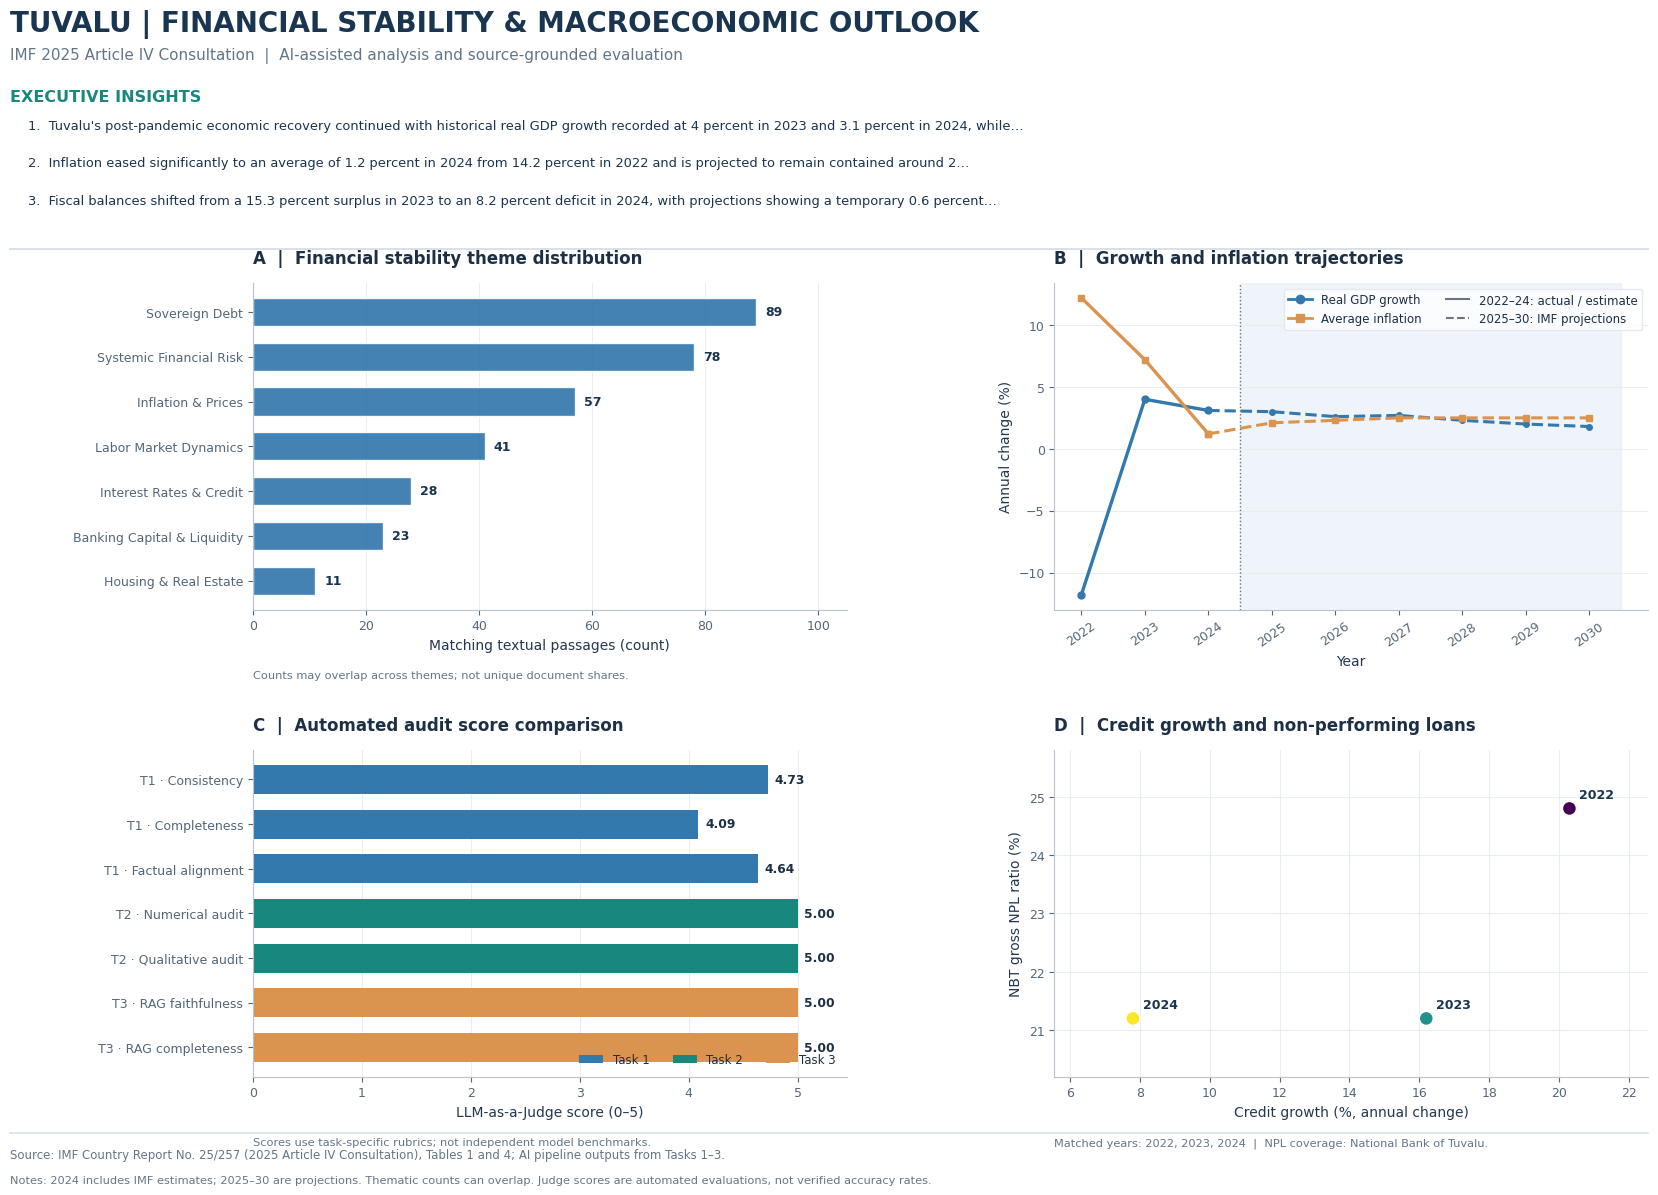


TASK 4 — FINAL VALIDATION
country: Tuvalu
plots_generated: 4
pd_melt_applied: True
executive_overlay: True
figure_dpi: 350
image_dimensions: [6300, 4375]
figure_formats: ['PNG', 'PDF', 'SVG']
trend_data_grounded: True
missing_values_not_plotted_as_zero: True
dashboard_png: Tuvalu_IMF_Executive_Dashboard_350dpi.png
dashboard_pdf: Tuvalu_IMF_Executive_Dashboard.pdf
dashboard_svg: Tuvalu_IMF_Executive_Dashboard.svg

FILES GENERATED
 - Tuvalu_IMF_Executive_Dashboard.pdf
 - Tuvalu_IMF_Executive_Dashboard.svg
 - Tuvalu_IMF_Executive_Dashboard_350dpi.png
 - credit_vs_npl.csv
 - dashboard_analysis_notes.json
 - dashboard_metadata.json
 - indicator_tidy_melted.csv
 - indicator_wide.csv
 - model_evaluation_comparison.csv
 - task4_validation.json
 - thematic_distribution.csv

TASK 4 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# TASK 4: PROFESSIONAL 4-PANEL IMF DASHBOARD
# High Resolution | Executive Overlay | Publication-Ready
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
import textwrap

# ---------------- 1. Visual style ----------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "savefig.dpi": 350,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#B9C4D0",
    "axes.labelcolor": "#23384E",
    "text.color": "#1B3045",
    "xtick.color": "#536778",
    "ytick.color": "#536778",
    "grid.color": "#E7ECF1",
    "grid.alpha": 0.85
})

NAVY = "#19354F"
BLUE = "#3479AD"
TEAL = "#18877C"
ORANGE = "#DA9450"
GREY = "#637688"
LIGHT = "#F2F6FA"

# Create a single 4-panel dashboard with room for
# the executive insight overlay and methodology footer.
fig = plt.figure(figsize=(18, 12.5), facecolor="white")

grid = GridSpec(
    2, 2,
    figure=fig,
    left=0.19,
    right=0.965,
    bottom=0.12,
    top=0.755,
    hspace=0.43,
    wspace=0.35
)

ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 1])
ax3 = fig.add_subplot(grid[1, 0])
ax4 = fig.add_subplot(grid[1, 1])

# ---------------- 2. Dashboard header ----------------

fig.text(
    0.055, 0.974,
    "TUVALU | FINANCIAL STABILITY & MACROECONOMIC OUTLOOK",
    fontsize=20,
    fontweight="bold",
    color=NAVY,
    va="top"
)

fig.text(
    0.055, 0.944,
    "IMF 2025 Article IV Consultation  |  "
    "AI-assisted analysis and source-grounded evaluation",
    fontsize=11,
    color=GREY,
    va="top"
)

# ---------------- 3. Executive text overlay ----------------

# Use findings actually generated in Task 1.
# Limit text length to keep the overlay readable.
callouts = executive_lines[:3]

def compact_text(s, width=145):
    return textwrap.shorten(
        s,
        width=width,
        placeholder="…"
    )

fig.text(
    0.055, 0.910,
    "EXECUTIVE INSIGHTS",
    fontsize=11.5,
    fontweight="bold",
    color=TEAL,
    va="top"
)

for i, insight in enumerate(callouts):
    fig.text(
        0.065,
        0.886 - i * 0.030,
        f"{i+1}.  {compact_text(insight)}",
        fontsize=9.4,
        color=NAVY,
        va="top"
    )

fig.add_artist(
    Line2D(
        [0.055, 0.965],
        [0.782, 0.782],
        transform=fig.transFigure,
        color="#D7E0E9",
        linewidth=1.4
    )
)

# ---------------- PANEL 1: THEMATIC DISTRIBUTION ----------------

bars = ax1.barh(
    theme_df["Theme"],
    theme_df["Count"],
    color=BLUE,
    alpha=0.93,
    height=0.63,
    edgecolor="white"
)

for bar, count in zip(bars, theme_df["Count"]):
    ax1.text(
        bar.get_width() + max(1, theme_df["Count"].max()*0.018),
        bar.get_y() + bar.get_height()/2,
        f"{int(count)}",
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color=NAVY
    )

ax1.set_title(
    "A  |  Financial stability theme distribution",
    loc="left",
    pad=14
)
ax1.set_xlabel("Matching textual passages (count)")
ax1.grid(axis="x")
ax1.set_axisbelow(True)
ax1.set_xlim(
    0,
    max(1, theme_df["Count"].max())*1.18
)

ax1.text(
    0, -0.21,
    "Counts may overlap across themes; not unique document shares.",
    transform=ax1.transAxes,
    fontsize=8.2,
    color=GREY
)

# ---------------- PANEL 2: GDP AND INFLATION ----------------

series_styles = {
    "real_gdp_growth_pct": {
        "label": "Real GDP growth",
        "color": BLUE,
        "marker": "o"
    },
    "inflation_period_average_pct": {
        "label": "Average inflation",
        "color": ORANGE,
        "marker": "s"
    }
}

for indicator, style in series_styles.items():
    subset = macro_df[
        macro_df["Indicator"] == indicator
    ].sort_values("Year")

    historical = subset[subset["Year"] <= 2024]
    projected = subset[subset["Year"] >= 2024]

    ax2.plot(
        historical["Year"],
        historical["Value"],
        color=style["color"],
        marker=style["marker"],
        markersize=5,
        linewidth=2.4,
        linestyle="-",
        label=style["label"]
    )

    ax2.plot(
        projected["Year"],
        projected["Value"],
        color=style["color"],
        marker=style["marker"],
        markersize=4,
        linewidth=2.2,
        linestyle="--"
    )

ax2.axvspan(
    2024.5, 2030.5,
    color="#EAF2F8",
    alpha=0.8,
    zorder=0
)

ax2.axvline(
    2024.5,
    color=GREY,
    linestyle=":",
    linewidth=1
)

ax2.set_title(
    "B  |  Growth and inflation trajectories",
    loc="left",
    pad=14
)
ax2.set_ylabel("Annual change (%)")
ax2.set_xlabel("Year")
ax2.set_xticks(sorted(macro_df["Year"].unique()))
ax2.tick_params(axis="x", rotation=35)
ax2.grid(axis="y")
ax2.set_axisbelow(True)

legend_items = [
    Line2D(
        [0], [0], color=BLUE, marker="o",
        linewidth=2, label="Real GDP growth"
    ),
    Line2D(
        [0], [0], color=ORANGE, marker="s",
        linewidth=2, label="Average inflation"
    ),
    Line2D(
        [0], [0], color=GREY, linestyle="-",
        label="2022–24: actual / estimate"
    ),
    Line2D(
        [0], [0], color=GREY, linestyle="--",
        label="2025–30: IMF projections"
    )
]

ax2.legend(
    handles=legend_items,
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#E0E6ED",
    ncol=2
)

# ---------------- PANEL 3: EVALUATION COMPARISON ----------------

evaluation_sorted = evaluation_df.iloc[::-1].copy()

task_colors = {
    "Task 1": BLUE,
    "Task 2": TEAL,
    "Task 3": ORANGE
}

bar_colors = evaluation_sorted[
    "Task"
].map(task_colors).tolist()

bars3 = ax3.barh(
    evaluation_sorted["Metric"],
    evaluation_sorted["Score"],
    color=bar_colors,
    height=0.65
)

ax3.set_xlim(0, 5.45)
ax3.set_xticks([0, 1, 2, 3, 4, 5])
ax3.set_xlabel("LLM-as-a-Judge score (0–5)")
ax3.set_title(
    "C  |  Automated audit score comparison",
    loc="left",
    pad=14
)
ax3.grid(axis="x")
ax3.set_axisbelow(True)

for bar, score in zip(
    bars3, evaluation_sorted["Score"]
):
    ax3.text(
        score + 0.06,
        bar.get_y() + bar.get_height()/2,
        f"{score:.2f}",
        va="center",
        fontsize=8.8,
        fontweight="bold"
    )

ax3.legend(
    handles=[
        Patch(facecolor=task_colors[k], label=k)
        for k in task_colors
    ],
    loc="lower right",
    frameon=False,
    ncol=3
)

ax3.text(
    0, -0.21,
    "Scores use task-specific rubrics; not independent model benchmarks.",
    transform=ax3.transAxes,
    fontsize=8.2,
    color=GREY
)

# ---------------- PANEL 4: CREDIT GROWTH VS NPL ----------------

scatter = ax4.scatter(
    banking_df["Credit_Growth"],
    banking_df["NPL_Ratio"],
    s=105,
    c=banking_df["Year"],
    cmap="viridis",
    edgecolors="white",
    linewidths=1.2,
    zorder=3
)

for _, r in banking_df.iterrows():
    ax4.annotate(
        str(int(r["Year"])),
        (r["Credit_Growth"], r["NPL_Ratio"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color=NAVY
    )

ax4.set_title(
    "D  |  Credit growth and non-performing loans",
    loc="left",
    pad=14
)
ax4.set_xlabel("Credit growth (%, annual change)")
ax4.set_ylabel("NBT gross NPL ratio (%)")
ax4.grid(True)
ax4.set_axisbelow(True)

# Add breathing room around sparse observations.
x_min, x_max = banking_df["Credit_Growth"].agg(["min", "max"])
y_min, y_max = banking_df["NPL_Ratio"].agg(["min", "max"])

x_pad = max((x_max - x_min)*0.18, 1)
y_pad = max((y_max - y_min)*0.18, 1)

ax4.set_xlim(x_min-x_pad, x_max+x_pad)
ax4.set_ylim(y_min-y_pad, y_max+y_pad)

ax4.text(
    0, -0.21,
    f"Matched years: {', '.join(map(str, banking_df['Year']))}"
    "  |  NPL coverage: National Bank of Tuvalu.",
    transform=ax4.transAxes,
    fontsize=8.2,
    color=GREY
)

# ---------------- 4. Overall dashboard footer ----------------

fig.add_artist(
    Line2D(
        [0.055, 0.965],
        [0.075, 0.075],
        transform=fig.transFigure,
        color="#D7E0E9",
        linewidth=1.1
    )
)

fig.text(
    0.055, 0.055,
    "Source: IMF Country Report No. 25/257 "
    "(2025 Article IV Consultation), Tables 1 and 4; "
    "AI pipeline outputs from Tasks 1–3.",
    fontsize=8.5,
    color=GREY
)

fig.text(
    0.055, 0.035,
    "Notes: 2024 includes IMF estimates; "
    "2025–30 are projections. Thematic counts can overlap. "
    "Judge scores are automated evaluations, not verified accuracy rates.",
    fontsize=8.2,
    color=GREY
)

# ---------------- 5. Export high-resolution assets ----------------

PNG_FILE = DASH / "Tuvalu_IMF_Executive_Dashboard_350dpi.png"
PDF_FILE = DASH / "Tuvalu_IMF_Executive_Dashboard.pdf"
SVG_FILE = DASH / "Tuvalu_IMF_Executive_Dashboard.svg"

fig.savefig(
    PNG_FILE,
    dpi=350,
    facecolor="white"
)

fig.savefig(
    PDF_FILE,
    format="pdf",
    facecolor="white"
)

fig.savefig(
    SVG_FILE,
    format="svg",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ---------------- 6. Analytical annotations ----------------

# Read 2025 indicators directly without pivot/unstack.

def get_macro_value(indicator, year):
    values = macro_df.loc[
        (macro_df["Indicator"] == indicator) &
        (macro_df["Year"] == year),
        "Value"
    ]

    if len(values) != 1:
        raise ValueError(
            f"Expected one value for {indicator}, {year}; "
            f"found {len(values)}"
        )

    return float(values.iloc[0])

growth_2025 = get_macro_value(
    "real_gdp_growth_pct", 2025
)

inflation_2025 = get_macro_value(
    "inflation_period_average_pct", 2025
)

analysis_notes = {
    "thematic_distribution": (
        "The distribution measures relative narrative "
        "emphasis across seven financial stability themes. "
        "Categories may overlap and keyword matching does "
        "not establish actual economic risk magnitude."
    ),
    "macroeconomic_trends": (
        f"The IMF projects real GDP growth of "
        f"{growth_2025:.1f}% and average inflation of "
        f"{inflation_2025:.1f}% in 2025. "
        "The chart distinguishes earlier observations "
        "and estimates from IMF forecasts."
    ),
    "model_evaluation": (
        "Automated judge results support analysis of "
        "summarisation, extraction and grounded answering. "
        "The metrics differ across tasks and therefore "
        "do not constitute a controlled model benchmark."
    ),
    "banking_stability": (
        f"Credit growth and the NBT gross NPL ratio are "
        f"compared across {len(banking_df)} matched years. "
        "A limited time series cannot establish a causal "
        "relationship between credit growth and NPLs."
    )
}

save_json(
    DASH / "dashboard_analysis_notes.json",
    analysis_notes
)

# ---------------- 7. Validate exported artifacts ----------------

for path in [PNG_FILE, PDF_FILE, SVG_FILE]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(f"Dashboard export failed: {path}")

from PIL import Image
with Image.open(PNG_FILE) as img:
    width_px, height_px = img.size

assert width_px >= 5000
assert height_px >= 3000

dashboard_validation = {
    "country": "Tuvalu",
    "plots_generated": 4,
    "pd_melt_applied": True,
    "executive_overlay": True,
    "figure_dpi": 350,
    "image_dimensions": [width_px, height_px],
    "figure_formats": ["PNG", "PDF", "SVG"],
    "trend_data_grounded": True,
    "missing_values_not_plotted_as_zero": True,
    "dashboard_png": PNG_FILE.name,
    "dashboard_pdf": PDF_FILE.name,
    "dashboard_svg": SVG_FILE.name
}

save_json(
    DASH / "task4_validation.json",
    dashboard_validation
)

print("\n" + "="*65)
print("TASK 4 — FINAL VALIDATION")
print("="*65)

for key, value in dashboard_validation.items():
    print(f"{key}: {value}")

print("\nFILES GENERATED")
for path in sorted(DASH.iterdir()):
    if path.is_file():
        print(f" - {path.name}")

print("\nTASK 4 COMPLETED SUCCESSFULLY")



[1/6] Q1: What financial regulation and supervisory improvements does the IMF recommend for Tuvalu's Banking Commission and banks?
  Baseline faithfulness: 5/5
  Multi-Query faithfulness: 5/5
  Multi-Query completeness: 5/5
  Candidate source pages: 16

[2/6] Q2: What does the IMF report say about banking capital adequacy, non-performing loans and associated financial-sector vulnerabilities?
  Baseline faithfulness: 5/5
  Multi-Query faithfulness: 5/5
  Multi-Query completeness: 5/5
  Candidate source pages: 25

[3/6] Q3: Why is Tuvalu assessed to be at high risk of debt distress, and what fiscal buffer and consolidation measures does the IMF recommend?
  Baseline faithfulness: 5/5
  Multi-Query faithfulness: 5/5
  Multi-Query completeness: 5/5
  Candidate source pages: 22

[4/6] Q4: How has inflation evolved in Tuvalu since 2022, what drives inflation, and what is the medium-term inflation outlook?
  Baseline faithfulness: 5/5
  Multi-Query faithfulness: 5/5
  Multi-Query completenes

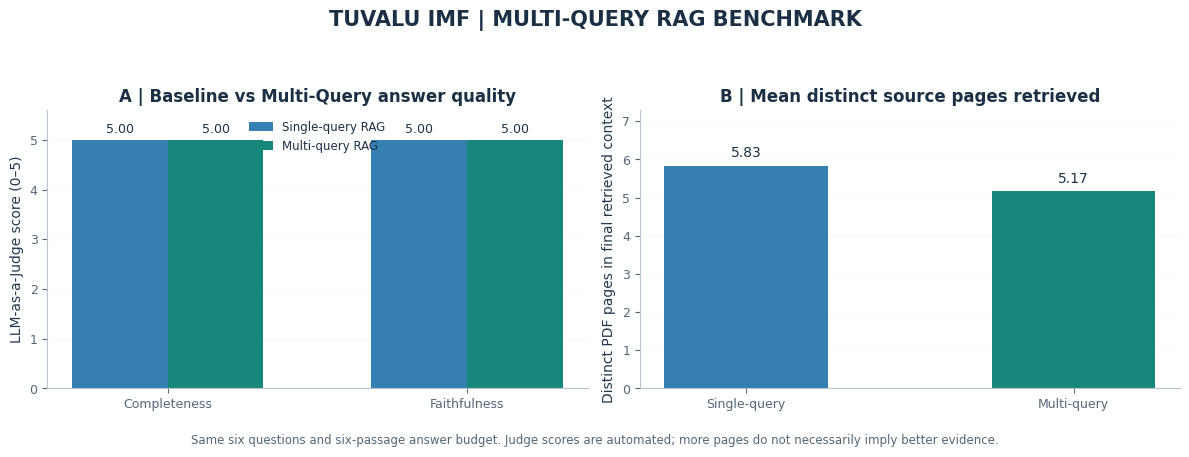


BONUS EXTENSION — FINAL RESULTS


,Question,Baseline_Completeness,Multi_Completeness,Baseline_Faithfulness,Multi_Faithfulness,Additional_Evidence_Pages,Multi_Abstained
0,Q1,5.0,5.0,5.0,5.0,1,False
1,Q2,5.0,5.0,5.0,5.0,3,False
2,Q3,5.0,5.0,5.0,5.0,0,False
3,Q4,5.0,5.0,5.0,5.0,0,False
4,Q5,5.0,5.0,5.0,5.0,0,False
5,Q6,5.0,5.0,5.0,5.0,0,True



BENCHMARK SUMMARY
country: Tuvalu
report_year: 2025
extension: Multi-Query RAG
embedding_model: sentence-transformers/all-MiniLM-L6-v2
generation_model: gemini-3.5-flash-lite
retrieval_index: FAISS IndexFlatL2
questions_tested: 6
query_variations_per_question: 3
queries_per_multiquery_search: 4
final_passages_per_answer: 6
fusion_method: Reciprocal Rank Fusion
rrf_constant: 60
baseline_mean_completeness: 5.0
multi_mean_completeness: 5.0
completeness_improvement: 0.0
baseline_mean_faithfulness: 5.0
multi_mean_faithfulness: 5.0
faithfulness_improvement: 0.0
mean_baseline_evidence_pages: 5.833
mean_multi_evidence_pages: 5.167
total_additional_selected_pages: 4
total_multi_unsupported_claims: 0
total_multi_citation_issues: 0
negative_control_abstained: True
evaluation_limitation: Baseline judge scores were already at the 5/5 ceiling. Retrieval diversity does not independently prove higher answer quality. Both systems use the same generative model and automated evaluator.
comparison_conclu

In [ ]:

# ============================================================
# MULTI-QUERY RAG BENCHMARK
# Baseline Single-Query vs Multi-Query FAISS Retrieval
#
# Reuses:
# - MiniLM embeddings + FAISS from Task 3
# - Gemini API wrapper and disk caching
# - Original six RAG questions and baseline evaluations
# - Existing RAG evaluator and prompt directives
#
# Fair comparison: same 6 passages and same judge rubric.
# ============================================================

import json, re, time, hashlib
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- 1. Setup and source validation ----------------

BONUS = ROOT / "bonus_multiquery"
BONUS.mkdir(parents=True, exist_ok=True)

baseline_answers = read_json(
    RAG_DIR / "rag_answers.json"
)
baseline_audits = read_json(
    RAG_DIR / "rag_evaluations.json"
)

assert len(RAG_QUESTIONS) == 6
assert set(RAG_QUESTIONS) == set(baseline_answers)
assert set(RAG_QUESTIONS) == set(baseline_audits)
assert faiss_index.ntotal == len(rag_corpus)

TOP_K = 6
VARIATIONS = 3
RRF_K = 60
EXTENSION_VERSION = "multiquery_tuvalu_v1"

# ---------------- 2. Generate query variations ----------------

QUERY_SYSTEM = """
You are an IMF financial research query-rewriting assistant.

Generate exactly three distinct search-query variations
that help retrieve complementary evidence from an IMF report.

Requirements:
- Preserve the original question's factual intent.
- Retain country names, years, institutions and metrics.
- Use alternate economic terminology where appropriate.
- Target complementary evidence from different report passages.
- Do not answer the question.
- Do not invent policy recommendations or numerical results.
- Do not turn an unavailable metric into a different metric.
- Preserve the distinction between Tier 1 capital and
  general capital adequacy.
- Return a JSON object containing a "queries" array.
"""

def generate_query_variations(question):
    prompt = f"""
ORIGINAL QUESTION:
{question}

Create exactly three diverse retrieval-query variations.

Return:
{{
  "queries": [
    "First search query",
    "Second search query",
    "Third search query"
  ]
}}
"""

    raw = gemini_call(
        QUERY_SYSTEM,
        prompt,
        max_tokens=500,
        json_mode=True,
        temperature=0
    )

    data = json.loads(raw)
    queries = data.get("queries", [])

    if not isinstance(queries, list):
        raise ValueError("Invalid query expansion output.")

    # Remove empty or duplicate variations.
    seen = {question.strip().casefold()}
    cleaned = []

    for query in queries:
        if not isinstance(query, str):
            continue

        query = query.strip()
        key = query.casefold()

        if query and key not in seen:
            cleaned.append(query)
            seen.add(key)

    if len(cleaned) != VARIATIONS:
        raise ValueError(
            "Expected three distinct query variations; "
            f"received {len(cleaned)}."
        )

    return cleaned

# ---------------- 3. Multi-query FAISS retrieval ----------------

def multiquery_retrieve(question, variations, top_k=6):
    """
    Search the existing local FAISS index for each variation,
    then apply Reciprocal Rank Fusion.

    The final evidence budget matches baseline RAG:
    at most six passages, with no more than two per page.
    """

    all_queries = [question] + list(variations)
    rankings = []
    union_ids = set()
    union_pages = set()

    for query in all_queries:
        retrieved = retrieve_evidence(
            query,
            top_k=12,
            pool=60
        )
        rankings.append(retrieved)

        for result in retrieved:
            union_ids.add(result["chunk_id"])
            union_pages.add(result["pdf_page"])

    fused_scores = {}
    evidence_lookup = {}

    for ranking in rankings:
        for rank, result in enumerate(ranking, start=1):
            cid = result["chunk_id"]

            fused_scores[cid] = (
                fused_scores.get(cid, 0.0)
                + 1.0 / (RRF_K + rank)
            )

            evidence_lookup[cid] = result

    ordered_ids = sorted(
        fused_scores,
        key=lambda cid: (-fused_scores[cid], cid)
    )

    final = []
    page_counts = {}

    for cid in ordered_ids:
        source = evidence_lookup[cid]
        page = int(source["pdf_page"])

        if page_counts.get(page, 0) >= 2:
            continue

        final.append({
            "chunk_id": cid,
            "pdf_page": page,
            "similarity": source["similarity"],
            "rrf_score": round(fused_scores[cid], 7),
            "text": source["text"]
        })

        page_counts[page] = page_counts.get(page, 0) + 1

        if len(final) == top_k:
            break

    if not final:
        raise ValueError(
            "No evidence retrieved by Multi-Query RAG."
        )

    return {
        "retrieved": final,
        "query_variations": list(variations),
        "candidate_chunks": len(union_ids),
        "candidate_pages": len(union_pages),
        "candidate_page_ids": sorted(union_pages),
        "queries_searched": len(all_queries)
    }

# ---------------- 4. Generate grounded Multi-Query answers ----------------

def generate_multiquery_answer(question, retrieval):
    evidence = retrieval["retrieved"]

    context = "\n\n".join(
        f"[{item['chunk_id']}] "
        f"PDF PAGE {item['pdf_page']}\n"
        f"{item['text']}"
        for item in evidence
    )

    prompt = f"""
REPORT: Tuvalu 2025 Article IV Consultation

ORIGINAL QUESTION:
{question}

RETRIEVED IMF EVIDENCE:
{context}

Answer the ORIGINAL question only from the retrieved
source passages. Do not use external facts.

Return the required JSON response, with citations
restricted to the available chunk IDs.
"""

    raw = gemini_call(
        RAG_SYSTEM,
        prompt,
        max_tokens=900,
        json_mode=True,
        temperature=0
    )

    response = json.loads(raw)

    required = [
        "answer", "citations", "abstained", "reason"
    ]
    if any(field not in response for field in required):
        raise ValueError(
            "Multi-Query answer has missing JSON fields."
        )

    if not isinstance(response["answer"], str):
        raise ValueError("Answer must be text.")

    if not isinstance(response["citations"], list):
        raise ValueError("Citations must be a list.")

    if not isinstance(response["abstained"], bool):
        raise ValueError("Abstained must be boolean.")

    if not isinstance(response["reason"], str):
        raise ValueError("Reason must be text.")

    allowed = {
        item["chunk_id"] for item in evidence
    }

    if any(cid not in allowed for cid in response["citations"]):
        raise ValueError(
            "Multi-Query answer contains invented citation IDs."
        )

    if (
        not response["abstained"]
        and not response["citations"]
    ):
        raise ValueError(
            "An asserted RAG answer must cite evidence."
        )

    response["question"] = question
    response["retrieved_evidence"] = evidence
    response["cited_pdf_pages"] = sorted(set(
        item["pdf_page"]
        for item in evidence
        if item["chunk_id"] in response["citations"]
    ))

    return response

# ---------------- 5. Cached execution over six questions ----------------

variation_file = BONUS / "query_variations.json"
multi_file = BONUS / "multiquery_answers.json"
audit_file = BONUS / "multiquery_evaluations.json"

query_variations = (
    read_json(variation_file)
    if variation_file.exists() else {}
)

multi_answers = (
    read_json(multi_file)
    if multi_file.exists() else {}
)

multi_audits = (
    read_json(audit_file)
    if audit_file.exists() else {}
)

for index, (qid, question) in enumerate(
    RAG_QUESTIONS.items(), 1
):
    print(f"\n[{index}/6] {qid}: {question}")

    # Generate variants only once.
    if (
        qid not in query_variations
        or query_variations[qid].get("question") != question
    ):
        variants = generate_query_variations(question)

        query_variations[qid] = {
            "question": question,
            "variations": variants
        }

        save_json(variation_file, query_variations)

    else:
        variants = query_variations[qid]["variations"]

    # Generate Multi-Query answer and save checkpoint.
    if (
        qid not in multi_answers
        or multi_answers[qid].get("question") != question
    ):
        retrieval = multiquery_retrieve(
            question, variants, top_k=TOP_K
        )

        result = generate_multiquery_answer(
            question, retrieval
        )

        result["query_variations"] = variants
        result["candidate_chunks"] = (
            retrieval["candidate_chunks"]
        )
        result["candidate_pages"] = (
            retrieval["candidate_pages"]
        )
        result["candidate_page_ids"] = (
            retrieval["candidate_page_ids"]
        )
        result["queries_searched"] = (
            retrieval["queries_searched"]
        )

        multi_answers[qid] = result
        save_json(multi_file, multi_answers)

    else:
        print("  Reusing saved Multi-Query answer.")

    # Apply the exact same judge function as Task 3.
    if qid not in multi_audits:
        multi_audits[qid] = evaluate_rag(
            qid, multi_answers[qid]
        )
        save_json(audit_file, multi_audits)

    print(
        f"  Baseline faithfulness: "
        f"{baseline_audits[qid]['faithfulness']}/5"
    )
    print(
        f"  Multi-Query faithfulness: "
        f"{multi_audits[qid]['faithfulness']}/5"
    )
    print(
        f"  Multi-Query completeness: "
        f"{multi_audits[qid]['completeness']}/5"
    )
    print(
        f"  Candidate source pages: "
        f"{multi_answers[qid]['candidate_pages']}"
    )

# ---------------- 6. Comparative evaluation ----------------

rows = []

for qid in RAG_QUESTIONS:
    base = baseline_audits[qid]
    multi = multi_audits[qid]

    base_answer = baseline_answers[qid]
    multi_answer = multi_answers[qid]

    base_chunks = {
        item["chunk_id"]
        for item in base_answer["retrieved_evidence"]
    }
    multi_chunks = {
        item["chunk_id"]
        for item in multi_answer["retrieved_evidence"]
    }

    base_pages = {
        int(item["pdf_page"])
        for item in base_answer["retrieved_evidence"]
    }
    multi_pages = {
        int(item["pdf_page"])
        for item in multi_answer["retrieved_evidence"]
    }

    rows.append({
        "Question": qid,
        "Baseline_Completeness": float(
            base["completeness"]
        ),
        "Multi_Completeness": float(
            multi["completeness"]
        ),
        "Baseline_Faithfulness": float(
            base["faithfulness"]
        ),
        "Multi_Faithfulness": float(
            multi["faithfulness"]
        ),
        "Completeness_Delta": round(
            float(multi["completeness"])
            - float(base["completeness"]), 2
        ),
        "Faithfulness_Delta": round(
            float(multi["faithfulness"])
            - float(base["faithfulness"]), 2
        ),
        "Baseline_Evidence_Pages": len(base_pages),
        "Multi_Evidence_Pages": len(multi_pages),
        "Additional_Evidence_Pages": len(
            multi_pages - base_pages
        ),
        "Shared_Chunks": len(
            base_chunks & multi_chunks
        ),
        "Multi_Candidate_Pages": int(
            multi_answer["candidate_pages"]
        ),
        "Baseline_Abstained": bool(
            base_answer["abstained"]
        ),
        "Multi_Abstained": bool(
            multi_answer["abstained"]
        ),
        "Multi_Unsupported_Claims": len(
            multi.get("unsupported_claims", [])
        ),
        "Multi_Citation_Issues": len(
            multi.get("citation_issues", [])
        )
    })

comparison = pd.DataFrame(rows)

comparison.to_csv(
    BONUS / "multiquery_comparison.csv",
    index=False
)

# ---------------- 7. Aggregate benchmark statistics ----------------

def avg(column):
    return round(float(comparison[column].mean()), 3)

benchmark = {
    "country": "Tuvalu",
    "report_year": 2025,
    "extension": "Multi-Query RAG",
    "embedding_model": EMBED_MODEL,
    "generation_model": MODEL,
    "retrieval_index": "FAISS IndexFlatL2",
    "questions_tested": len(RAG_QUESTIONS),
    "query_variations_per_question": VARIATIONS,
    "queries_per_multiquery_search": VARIATIONS + 1,
    "final_passages_per_answer": TOP_K,
    "fusion_method": "Reciprocal Rank Fusion",
    "rrf_constant": RRF_K,
    "baseline_mean_completeness":
        avg("Baseline_Completeness"),
    "multi_mean_completeness":
        avg("Multi_Completeness"),
    "completeness_improvement":
        avg("Completeness_Delta"),
    "baseline_mean_faithfulness":
        avg("Baseline_Faithfulness"),
    "multi_mean_faithfulness":
        avg("Multi_Faithfulness"),
    "faithfulness_improvement":
        avg("Faithfulness_Delta"),
    "mean_baseline_evidence_pages":
        avg("Baseline_Evidence_Pages"),
    "mean_multi_evidence_pages":
        avg("Multi_Evidence_Pages"),
    "total_additional_selected_pages":
        int(comparison["Additional_Evidence_Pages"].sum()),
    "total_multi_unsupported_claims":
        int(comparison["Multi_Unsupported_Claims"].sum()),
    "total_multi_citation_issues":
        int(comparison["Multi_Citation_Issues"].sum()),
    "negative_control_abstained":
        bool(multi_answers["Q6"]["abstained"]),
    "evaluation_limitation": (
        "Baseline judge scores were already at the 5/5 "
        "ceiling. Retrieval diversity does not independently "
        "prove higher answer quality. Both systems use the "
        "same generative model and automated evaluator."
    )
}

benchmark["comparison_conclusion"] = (
    "Multi-Query produced higher mean completeness."
    if benchmark["completeness_improvement"] > 0
    else (
        "Multi-Query reduced mean completeness."
        if benchmark["completeness_improvement"] < 0
        else "Multi-Query did not improve mean completeness."
    )
)

save_json(
    BONUS / "multiquery_benchmark_summary.json",
    benchmark
)

save_json(
    BONUS / "multiquery_complete_results.json",
    {
        "metadata": benchmark,
        "query_variations": query_variations,
        "comparison": comparison.to_dict(
            orient="records"
        ),
        "multiquery_answers": multi_answers,
        "multiquery_evaluations": multi_audits
    }
)

# ---------------- 8. Visual benchmark comparison ----------------

metrics = ["Completeness", "Faithfulness"]
base_scores = [
    benchmark["baseline_mean_completeness"],
    benchmark["baseline_mean_faithfulness"]
]
multi_scores = [
    benchmark["multi_mean_completeness"],
    benchmark["multi_mean_faithfulness"]
]

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5)
)

x = np.arange(len(metrics))
width = 0.32

bars_base = axes[0].bar(
    x - width/2, base_scores, width,
    label="Single-query RAG",
    color="#367FB2"
)

bars_multi = axes[0].bar(
    x + width/2, multi_scores, width,
    label="Multi-query RAG",
    color="#17877B"
)

axes[0].set_xticks(x, metrics)
axes[0].set_ylim(0, 5.6)
axes[0].set_ylabel("LLM-as-a-Judge score (0–5)")
axes[0].set_title(
    "A | Baseline vs Multi-Query answer quality"
)
axes[0].legend(frameon=False, loc="upper center")
axes[0].grid(axis="y", alpha=0.25)
axes[0].set_axisbelow(True)

for bars in [bars_base, bars_multi]:
    axes[0].bar_label(
        bars, fmt="%.2f", padding=3, fontsize=9
    )

page_comparison = comparison[
    ["Baseline_Evidence_Pages", "Multi_Evidence_Pages"]
].mean()

bars = axes[1].bar(
    ["Single-query", "Multi-query"],
    page_comparison.values,
    color=["#367FB2", "#17877B"],
    width=0.5
)

axes[1].set_title(
    "B | Mean distinct source pages retrieved"
)
axes[1].set_ylabel(
    "Distinct PDF pages in final retrieved context"
)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)
axes[1].bar_label(
    bars, fmt="%.2f", padding=4
)
axes[1].set_ylim(
    0, max(1, float(page_comparison.max()) * 1.25)
)

fig.suptitle(
    "TUVALU IMF | MULTI-QUERY RAG BENCHMARK",
    fontsize=15, fontweight="bold"
)

fig.text(
    0.5, 0.015,
    "Same six questions and six-passage answer budget. "
    "Judge scores are automated; more pages do not "
    "necessarily imply better evidence.",
    ha="center", fontsize=8.5, color="#536778"
)

fig.tight_layout(rect=[0, 0.055, 1, 0.92])

fig.savefig(
    BONUS / "MultiQuery_RAG_Benchmark_350dpi.png",
    dpi=350, bbox_inches="tight"
)
fig.savefig(
    BONUS / "MultiQuery_RAG_Benchmark.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ---------------- 9. Final validation ----------------

assert len(comparison) == 6
assert comparison[
    ["Baseline_Completeness",
     "Multi_Completeness",
     "Baseline_Faithfulness",
     "Multi_Faithfulness"]
].apply(lambda s: s.between(0, 5).all()).all()

assert all(
    len(multi_answers[q]["retrieved_evidence"]) <= TOP_K
    for q in RAG_QUESTIONS
)

assert all(
    set(multi_answers[q]["citations"]).issubset({
        e["chunk_id"]
        for e in multi_answers[q]["retrieved_evidence"]
    })
    for q in RAG_QUESTIONS
)

print("\n" + "=" * 65)
print("BONUS EXTENSION — FINAL RESULTS")
print("=" * 65)

display(comparison[[
    "Question",
    "Baseline_Completeness",
    "Multi_Completeness",
    "Baseline_Faithfulness",
    "Multi_Faithfulness",
    "Additional_Evidence_Pages",
    "Multi_Abstained"
]])

print("\nBENCHMARK SUMMARY")
for key, value in benchmark.items():
    print(f"{key}: {value}")

print("\nBONUS OUTPUT FILES")
for path in sorted(BONUS.iterdir()):
    if path.is_file():
        print(" -", path.name)

print("\nCELL 14 — BONUS EXTENSION COMPLETED SUCCESSFULLY")


In [24]:
from pathlib import Path

base = Path("/content/Tuvalu_IMF_Task1")
zip_file = Path("/content/Tuvalu_IMF_Assessment_Outputs.zip")

print("Results folder exists:", base.exists())

for folder in ["task2", "task3", "task4", "bonus_multiquery"]:
    print(f"{folder}:", (base / folder).exists())

print("ZIP file exists:", zip_file.exists())

Results folder exists: True
task2: True
task3: True
task4: True
bonus_multiquery: True
ZIP file exists: False


In [25]:

import zipfile
from pathlib import Path

source = Path("/content/Tuvalu_IMF_Task1")
destination = Path("/content/Tuvalu_IMF_Assessment_Outputs.zip")

assert source.is_dir(), "Assessment results folder is missing."

with zipfile.ZipFile(
    destination,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    allowZip64=True
) as archive:
    for file in source.rglob("*"):
        if not file.is_file():
            continue

        relative = file.relative_to(source)

        # Do not package cached API calls or potential secrets.
        if "cache" in relative.parts:
            continue
        if file.suffix.lower() in {".env", ".key", ".pem"}:
            continue

        archive.write(file, arcname=str(relative))

# Verify archive integrity.
with zipfile.ZipFile(destination) as archive:
    assert archive.testzip() is None, "ZIP integrity check failed."
    count = len(archive.namelist())

print("ZIP CREATED SUCCESSFULLY")
print("File:", destination)
print("Size:", round(destination.stat().st_size / 1024**2, 2), "MB")
print("Files included:", count)


ZIP CREATED SUCCESSFULLY
File: /content/Tuvalu_IMF_Assessment_Outputs.zip
Size: 2.59 MB
Files included: 59
